# 6BUIS017W CWK1 — Market Analysis and Stock Segmentation Using RFM

S&P 500 shares segmented by risk and return (mean weekly return, weekly beta) and by adapted RFM trading activity.
Study period: 1 Jan 2021 – 1 Jan 2025 (end exclusive).

**GitHub repository:**

# 0. Setup

### 0.1 Install packages

In [1]:
# Install / upgrade yfinance (Yahoo Finance downloader)
!pip install -q --upgrade yfinance

### 0.2 Import libraries

In [2]:
# Standard libraries for files, JSON, timing and timestamps
import os
import json
import time
from io import StringIO
from datetime import datetime, timezone

# Data handling, web requests and Yahoo Finance
import numpy as np
import pandas as pd
import requests
import yfinance as yf

### 0.3 Study settings
End date is exclusive, so data run to 31 Dec 2024.

In [3]:
# Study settings from the brief
START = "2021-01-01"
END = "2025-01-01"        # exclusive -> last day downloaded is 2024-12-31
BENCHMARK = "^GSPC"       # S&P 500 index
SEED = 42                 # fixed random seed, used later in K-Means
DATA_SOURCE = "live"      # "live" = download now; "cached" = reload saved snapshot (see 1.1.3 f)

np.random.seed(SEED)
pd.set_option("display.float_format", "{:,.6f}".format)   # show numbers without scientific notation

### 0.4 Project folders

In [4]:
# Create folders for raw data, processed data, charts and logs
for folder in ["data/raw", "data/processed", "figures", "logs"]:
    os.makedirs(folder, exist_ok=True)

### 0.5 Package versions

In [5]:
import sklearn, scipy, matplotlib, seaborn

# Record package versions for reproducibility
versions = {
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "yfinance": yf.__version__,
    "scikit-learn": sklearn.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": seaborn.__version__,
}

# Save versions to requirements.txt
with open("requirements.txt", "w") as f:
    for name, version in versions.items():
        f.write(f"{name}=={version}\n")

versions

{'pandas': '2.2.3',
 'numpy': '2.4.6',
 'yfinance': '1.8.0',
 'scikit-learn': '1.6.1',
 'scipy': '1.16.3',
 'matplotlib': '3.10.0',
 'seaborn': '0.13.2'}

# 1.1 Ticker selection and data acquisition
Sources: Wikipedia constituents table; Yahoo Finance via `yfinance` (maintained, batch downloads, returns Close, Adj Close, Volume, dividends and splits).

## 1.1.1 S&P 500 ticker list

### (a) Download the Wikipedia page
Retrieval time recorded in UTC.

In [6]:
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
# A browser-like header so Wikipedia does not block the request
headers = {"User-Agent": "Mozilla/5.0 (University coursework 6BUIS017W)"}

response = requests.get(WIKI_URL, headers=headers, timeout=30)
response.raise_for_status()      # stops here if the page did not download

# Record the retrieval time (UTC)
wiki_retrieved_utc = datetime.now(timezone.utc).isoformat(timespec="seconds")
print("Wikipedia retrieved at (UTC):", wiki_retrieved_utc)

Wikipedia retrieved at (UTC): 2026-11-23T11:34:41+00:00


### (b) Read the constituents table

In [7]:
# Read the table with id 'constituents' from the page
sp500 = pd.read_html(StringIO(response.text), attrs={"id": "constituents"})[0]

print("Number of rows:", len(sp500))
sp500.head()

Number of rows: 503


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


### (c) Convert tickers to Yahoo format (e.g. BRK.B → BRK-B)

In [8]:
# Yahoo uses '-' instead of '.' in share-class tickers
sp500["yahoo_ticker"] = sp500["Symbol"].str.replace(".", "-", regex=False)

# Show which tickers were converted and check for duplicates
changed = sp500[sp500["Symbol"] != sp500["yahoo_ticker"]]
print("Tickers converted:", changed[["Symbol", "yahoo_ticker"]].values.tolist())
print("Duplicate tickers:", sp500["yahoo_ticker"].duplicated().sum())

Tickers converted: [['BRK.B', 'BRK-B'], ['BF.B', 'BF-B']]
Duplicate tickers: 0


### (d) Save the list and the raw page

In [9]:
# Save the ticker list and the raw HTML page
sp500.to_csv("data/raw/sp500_constituents.csv", index=False)

with open("data/raw/sp500_wikipedia_page.html", "w", encoding="utf-8") as f:
    f.write(response.text)

# List of tickers to download
tickers = sp500["yahoo_ticker"].tolist()
print("Tickers to download:", len(tickers))

Tickers to download: 503


## 1.1.2 Daily price and volume download

### (a) Download helper
`auto_adjust=False` keeps Close (for M) and Adj Close (for returns); `actions=True` adds dividends and splits.

In [10]:
# Columns kept for every share and day
COLUMNS = ["Date", "Ticker", "Open", "High", "Low", "Close", "Adj Close",
           "Volume", "Dividends", "Stock Splits"]

# Download tickers and reshape to one row per share per day
def download_long(ticker_list):
    # auto_adjust=False keeps both Close and Adj Close; actions=True adds dividends and splits
    wide = yf.download(ticker_list, start=START, end=END,
                       auto_adjust=False, actions=True,
                       group_by="column", multi_level_index=True,
                       progress=False, threads=True)
    # Return an empty table if nothing was downloaded
    if wide.empty:
        return pd.DataFrame(columns=COLUMNS)
    # Wide (one column per ticker) -> long (one row per ticker per day)
    long = wide.stack(level="Ticker", future_stack=True).reset_index()
    return long.reindex(columns=COLUMNS)

### (b) Test on three shares

In [11]:
# Small test download before the full run
test = download_long(["AAPL", "MSFT", "JPM"])

print(test.head())
# Close and Adj Close should differ (dividends)
print("\nIs Adj Close different from Close for AAPL?",
      not test.loc[test.Ticker == "AAPL", "Close"].equals(
          test.loc[test.Ticker == "AAPL", "Adj Close"]))

Price       Date Ticker       Open       High        Low      Close  \
0     2021-01-04   AAPL 133.520004 133.610001 126.760002 129.410004   
1     2021-01-04    JPM 127.500000 127.860001 124.779999 125.870003   
2     2021-01-04   MSFT 222.529999 223.000000 214.809998 217.690002   
3     2021-01-05   AAPL 128.889999 131.740005 128.429993 131.009995   
4     2021-01-05    JPM 124.989998 126.300003 123.769997 125.650002   

Price  Adj Close     Volume  Dividends  Stock Splits  
0     125.537094  143301900   0.000000      0.000000  
1     108.459435   16819900   0.000000      0.000000  
2     207.165207   37130100   0.000000      0.000000  
3     127.089211   97664900   0.000000      0.000000  
4     109.049583   13731200   0.900000      0.000000  

Is Adj Close different from Close for AAPL? True


### (c) Download in batches of 50
Missing values are not filled.

In [12]:
# Download in batches of 50 tickers to avoid being blocked
parts = []
for i in range(0, len(tickers), 50):
    group = tickers[i:i + 50]
    parts.append(download_long(group))
    print(f"Downloaded {min(i + 50, len(tickers))} of {len(tickers)}")
    time.sleep(2)

# Combine all batches into one table
prices = pd.concat(parts, ignore_index=True)

Downloaded 50 of 503
Downloaded 100 of 503
Downloaded 150 of 503


ERROR:yfinance:$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Downloaded 200 of 503


ERROR:yfinance:$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Downloaded 250 of 503
Downloaded 300 of 503
Downloaded 350 of 503


ERROR:yfinance:$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Downloaded 400 of 503


ERROR:yfinance:$SNDK: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Downloaded 450 of 503


ERROR:yfinance:$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Downloaded 500 of 503
Downloaded 503 of 503


### (d) Retry failures and log them

In [13]:
# A ticker has failed if it has no Close price at all
def failed_tickers(df):
    ok = df.dropna(subset=["Close"])["Ticker"].unique()
    return [t for t in tickers if t not in ok]

# Retry each failed ticker once
retry = failed_tickers(prices)
print("Failed on first attempt:", retry)

for t in retry:
    time.sleep(2)
    new = download_long([t]).dropna(subset=["Close"])
    if not new.empty:                                   # only add rows that actually contain data
        prices = pd.concat([prices[prices.Ticker != t], new], ignore_index=True)

# Tickers that still failed are recorded and removed
failed = failed_tickers(prices)
prices = prices[~prices.Ticker.isin(failed)]
print("Still failed after retry:", failed)

Failed on first attempt: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


ERROR:yfinance:$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:$SNDK: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfi

Still failed after retry: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


### (e) Benchmark (^GSPC)

In [14]:
# Download the S&P 500 index (benchmark)
bench = download_long([BENCHMARK])

print("Benchmark trading days:", bench["Close"].notna().sum())
print("From", bench.Date.min().date(), "to", bench.Date.max().date())

Benchmark trading days: 1005
From 2021-01-04 to 2024-12-31


### (f) Quick checks on the download

In [15]:
# Make sure dates are real dates
prices["Date"] = pd.to_datetime(prices["Date"])
bench["Date"] = pd.to_datetime(bench["Date"])

# Basic checks on the download
print("Close has data:    ", prices["Close"].notna().any())
print("Adj Close has data:", prices["Adj Close"].notna().any())
print("Share dates from", prices.Date.min().date(), "to", prices.Date.max().date())
print("Rows:", len(prices), "| Shares:", prices.Ticker.nunique())

Close has data:     True
Adj Close has data: True
Share dates from 2021-01-04 to 2024-12-31
Rows: 500490 | Shares: 498


**Result:** Close and Adj Close both available; the Close-only fallback is not needed.

## 1.1.3 Snapshot, provenance and acquisition log

### (a) Save the raw snapshot

In [16]:
# Save the untouched raw data (snapshot)
prices.to_parquet("data/raw/prices_daily_raw.parquet", index=False)
bench.to_parquet("data/raw/benchmark_gspc_raw.parquet", index=False)

### (b) Provenance metadata

In [17]:
# Provenance: source, retrieval times, package and settings
metadata = {
    "wikipedia_url": WIKI_URL,
    "wikipedia_retrieved_utc": wiki_retrieved_utc,
    "yahoo_retrieved_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "package": f"yfinance {yf.__version__}",
    "start": START,
    "end_exclusive": END,
    "auto_adjust": False,
    "benchmark": BENCHMARK,
    "data_source": DATA_SOURCE,
    "tickers_requested": len(tickers),
    "failed_downloads": failed,
}

# Save as JSON
with open("logs/acquisition_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

metadata

{'wikipedia_url': 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies',
 'wikipedia_retrieved_utc': '2026-11-23T11:34:41+00:00',
 'yahoo_retrieved_utc': '2026-11-23T11:36:38+00:00',
 'package': 'yfinance 1.8.0',
 'start': '2021-01-01',
 'end_exclusive': '2025-01-01',
 'auto_adjust': False,
 'benchmark': '^GSPC',
 'data_source': 'live',
 'tickers_requested': 503,
 'failed_downloads': ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']}

### (c) Acquisition log

In [18]:
# First date, last date and number of days for each downloaded share
coverage = (prices.dropna(subset=["Close"])
                  .groupby("Ticker")
                  .agg(first_date=("Date", "min"),
                       last_date=("Date", "max"),
                       n_days=("Close", "size")))

# Join with the ticker list; shares with no data are marked 'failed'
acq_log = sp500[["Symbol", "yahoo_ticker", "Security", "GICS Sector", "Date added"]].merge(
    coverage, left_on="yahoo_ticker", right_index=True, how="left")
acq_log["status"] = np.where(acq_log["n_days"].notna(), "downloaded", "failed")

# Save the acquisition log
acq_log.to_csv("logs/acquisition_log.csv", index=False)
acq_log["status"].value_counts()

,count
status,
downloaded,498
failed,5


### (d) Shares with shorter histories

In [19]:
# Full history = the longest number of trading days
full_length = acq_log["n_days"].max()
# Shares with fewer days than the full history
short = acq_log[acq_log["n_days"] < full_length]

print("Full history length:", int(full_length), "trading days")
print("Shares with shorter history:", len(short))
short[["yahoo_ticker", "Security", "first_date", "last_date", "n_days"]].sort_values("n_days")

Full history length: 1005 trading days
Shares with shorter history: 10


,yahoo_ticker,Security,first_date,last_date,n_days
211,GEV,GE Vernova,2024-03-27,2024-12-31,193.000000
415,SOLV,Solventum,2024-03-26,2024-12-31,194.000000
385,RDDT,Reddit,2024-03-21,2024-12-31,197.000000
466,VLTO,Veralto,2023-10-04,2024-12-31,313.000000
210,GEHC,GE HealthCare,2022-12-15,2024-12-31,513.000000
123,CEG,Constellation Energy,2022-01-19,2024-12-31,742.000000
393,HOOD,Robinhood Markets,2021-07-29,2024-12-31,862.000000
40,APP,AppLovin,2021-04-15,2024-12-31,935.000000
116,COIN,Coinbase,2021-04-14,2024-12-31,936.000000
181,EXE,Expand Energy,2021-02-10,2024-12-31,979.000000


**Result:** 10 late listings (excluded in 1.2.5); 5 tickers with no data for the period (FDXF, HONA, Q, SNDK, VYLR).

### (e) Download the snapshot

In [20]:
# Zip the snapshot and download it (Colab files are lost when the session ends)
!zip -qr cwk1_snapshot.zip data logs requirements.txt

from google.colab import files
files.download("cwk1_snapshot.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### (f) Cached mode
Set `DATA_SOURCE = "cached"` in 0.3 to reload the saved snapshot instead of downloading.

In [21]:
# Reload the saved snapshot instead of downloading (cached mode)
if DATA_SOURCE == "cached":
    sp500 = pd.read_csv("data/raw/sp500_constituents.csv")
    prices = pd.read_parquet("data/raw/prices_daily_raw.parquet")
    bench = pd.read_parquet("data/raw/benchmark_gspc_raw.parquet")
    prices["Date"], bench["Date"] = pd.to_datetime(prices["Date"]), pd.to_datetime(bench["Date"])
    acq_log = pd.read_csv("logs/acquisition_log.csv")
    with open("logs/acquisition_metadata.json") as f:
        metadata = json.load(f)
    metadata["data_source"] = "cached"
    failed = metadata["failed_downloads"]
    print("Using cached snapshot retrieved (UTC):", metadata["yahoo_retrieved_utc"])
else:
    print("Live data in use - nothing to reload.")

Live data in use - nothing to reload.


# 1.2 Data validation and alignment
**Inclusion rule:** valid Close, Adj Close and Volume on every trading day; prices > 0; volume > 0. No values are filled.

## 1.2.1 Trading calendar
^GSPC dates define the trading days.

In [22]:
# Use the benchmark's dates as the official trading calendar
rows_before = len(bench)
bench = bench.dropna(subset=["Close"]).sort_values("Date").reset_index(drop=True)
trading_days = pd.DatetimeIndex(bench["Date"], name="Date")
FIRST_DAY, LAST_DAY = trading_days.min(), trading_days.max()

# Report the calendar and check for duplicate dates
print("Benchmark rows without a price removed:", rows_before - len(bench))
print("Trading days:", len(trading_days), "| first:", FIRST_DAY.date(), "| last:", LAST_DAY.date())
print("Duplicate benchmark dates:", trading_days.duplicated().sum())

Benchmark rows without a price removed: 0
Trading days: 1005 | first: 2021-01-04 | last: 2024-12-31
Duplicate benchmark dates: 0


## 1.2.2 Duplicate dates
Exact duplicates removed; conflicting duplicates excluded.

In [23]:
# Counts before removing duplicates
rows_before, shares_before = len(prices), prices["Ticker"].nunique()

# Exact duplicate rows are identical copies, so they are removed
exact_dupes = prices.duplicated().sum()
prices = prices.drop_duplicates()

# Same share and date with different values = conflicting duplicates
conflicts = prices[prices.duplicated(["Ticker", "Date"], keep=False)]
dupe_tickers = sorted(conflicts["Ticker"].unique())

print("Rows before:", rows_before, "| shares before:", shares_before)
print("Exact duplicate rows removed:", exact_dupes)
print("Conflicting duplicate rows:", len(conflicts), "| shares affected:", dupe_tickers)
print("Rows after:", len(prices), "| shares still clear of duplicates:",
      shares_before - len(dupe_tickers))

Rows before: 500490 | shares before: 498
Exact duplicate rows removed: 0
Conflicting duplicate rows: 0 | shares affected: []
Rows after: 500490 | shares still clear of duplicates: 498


## 1.2.3 Missing values, non-positive prices, volume errors and unequal histories

### (a) Official trading days only

In [24]:
# Rows dated on days the market was closed
off_calendar = prices[~prices.Date.isin(trading_days) & prices.Close.notna()]
print("Share rows with data on non-trading days:", len(off_calendar))

# Keep trading days only and drop shares with conflicting duplicates
prices_cal = prices[prices.Date.isin(trading_days) & ~prices.Ticker.isin(dupe_tickers)]

Share rows with data on non-trading days: 0


### (b) Wide tables (days × shares)

In [25]:
# One table per field: rows = trading days, columns = shares (missing days stay empty)
def wide(field):
    table = prices_cal.pivot(index="Date", columns="Ticker", values=field)
    return table.reindex(trading_days).rename_axis("Date").astype(float)

close_w = wide("Close")
adj_w = wide("Adj Close")
vol_w = wide("Volume")
print("Table shape (days x shares):", close_w.shape)

Table shape (days x shares): (1005, 498)


### (c) Checks per share

In [26]:
# Count problems per share (0 = no problem)
checks = pd.DataFrame({
    "missing_close": close_w.isna().sum(),
    "missing_adj_close": adj_w.isna().sum(),
    "missing_volume": vol_w.isna().sum(),
    "nonpositive_price": ((close_w <= 0) | (adj_w <= 0)).sum(),
    "zero_volume": (vol_w == 0).sum(),
    "negative_volume": (vol_w < 0).sum(),
})
# Unequal histories: starts after the first day or ends before the last day
checks["starts_late"] = close_w.apply(pd.Series.first_valid_index) > FIRST_DAY
checks["ends_early"] = close_w.apply(pd.Series.last_valid_index) < LAST_DAY
# Missing days in the middle of a share's history
checks["gaps_inside_history"] = close_w.apply(
    lambda s: s.loc[s.first_valid_index():s.last_valid_index()].isna().sum())
checks.head()

,missing_close,missing_adj_close,missing_volume,nonpositive_price,zero_volume,negative_volume,starts_late,ends_early,gaps_inside_history
Ticker,,,,,,,,,
A,0,0,0,0,0,0,False,False,0
AAPL,0,0,0,0,0,0,False,False,0
ABBV,0,0,0,0,0,0,False,False,0
ABNB,0,0,0,0,0,0,False,False,0
ABT,0,0,0,0,0,0,False,False,0


### (d) Summary: how many shares fail each check

In [27]:
# Number of shares affected by each check
validation_summary = (checks > 0).sum().rename("shares_affected").to_frame()
validation_summary.to_csv("logs/validation_summary.csv")
validation_summary

,shares_affected
missing_close,10
missing_adj_close,10
missing_volume,10
nonpositive_price,0
zero_volume,2
negative_volume,0
starts_late,10
ends_early,0
gaps_inside_history,0


**Result:** 10 shares with missing values, all late listings; 0 gaps inside histories; 2 shares with zero-volume days (FERG, SW).

### (e) Zero-volume days

In [28]:
# List when each zero-volume share had zero-volume days
zero_vol_shares = checks.index[checks["zero_volume"] > 0]
for t in zero_vol_shares:
    zero_days = vol_w.index[vol_w[t] == 0]
    print(f"{t}: {len(zero_days)} zero-volume days, "
          f"first {zero_days.min().date()}, last {zero_days.max().date()}")

FERG: 27 zero-volume days, first 2021-01-07, last 2021-03-05
SW: 424 zero-volume days, first 2021-01-05, last 2024-07-05


**Result:** FERG has zero volume from 7 Jan to 5 Mar 2021 (NYSE trading began 8 Mar 2021); SW until 5 Jul 2024 (NYSE trading began 8 Jul 2024). These pre-listing records are not normal US trading histories, so both shares are excluded.

## 1.2.4 Corporate actions

### (a) Splits
If adjusted, split days show a normal Close change and a stable volume ratio.

In [29]:
# All split events and daily Close changes
splits = prices_cal.loc[prices_cal["Stock Splits"] > 0, ["Ticker", "Date", "Stock Splits"]].copy()
close_ret = close_w.pct_change(fill_method=None)

# Average volume in the 20 days after a split / 20 days before (about 1 if volume is split-adjusted)
def volume_ratio(ticker, date):
    v = vol_w[ticker]
    i = v.index.get_loc(date)
    return v.iloc[i:i + 20].mean() / v.iloc[i - 20:i].mean() if i >= 20 else np.nan

# Close change on the split day (small if prices are split-adjusted)
splits["close_change_on_split_day"] = [close_ret.at[d, t] for t, d in zip(splits.Ticker, splits.Date)]
splits["volume_after_vs_before"] = [volume_ratio(t, d) for t, d in zip(splits.Ticker, splits.Date)]
print("Split events in study period:", len(splits))
splits.round(3)

Split events in study period: 61


Price,Ticker,Date,Stock Splits,close_change_on_split_day,volume_after_vs_before
2135,APH,2021-03-05,2.000000,0.025000,0.920000
11130,ANET,2021-11-18,4.000000,0.004000,0.799000
16049,T,2022-04-11,1.324000,0.077000,1.317000
17929,AMZN,2022-06-06,20.000000,0.020000,0.757000
19344,GOOG,2022-07-18,20.000000,-0.025000,0.795000
...,...,...,...,...,...
467691,WRB,2022-03-24,1.500000,0.001000,1.325000
491790,WMT,2024-02-26,3.000000,0.018000,0.741000
496392,WSM,2024-07-09,2.000000,-0.003000,0.713000
496491,WRB,2024-07-11,1.500000,-0.015000,1.265000


**Result:** 61 splits with small Close changes and volume ratios near 1, so Close and Volume are adjusted consistently and Close × Volume is valid for M. The non-integer AT&T factor (Apr 2022) reflects a spin-off adjustment.

### (b) Dividends

In [30]:
# Number of shares that paid dividends
payers = prices_cal.loc[prices_cal["Dividends"] > 0, "Ticker"].nunique()
print("Shares that paid at least one dividend:", payers)

# Adj Close / Close: below 1 where past dividends have been adjusted for
adj_ratio = (adj_w / close_w).stack()
print("Adj Close / Close ratio: min", round(adj_ratio.min(), 3), "| max", round(adj_ratio.max(), 3))

Shares that paid at least one dividend: 399
Adj Close / Close ratio: min 0.646 | max 1.0


In [31]:
# ^GSPC is a price index: Adj Close should equal Close
gspc_same = np.allclose(bench["Adj Close"], bench["Close"])
print("^GSPC Adj Close equals Close on every day:", gspc_same)

^GSPC Adj Close equals Close on every day: True


**Result:** dividend payers have Adj Close ≠ Close; ^GSPC has Adj Close = Close (price index, no dividends). ^GSPC is kept as specified; the basis difference is a limitation.

### (c) Daily moves above 40% (reviewed, not deleted)

In [32]:
# Daily Adj Close returns for every share
adj_ret = adj_w.pct_change(fill_method=None)
moves = adj_ret.reset_index().melt(id_vars="Date", var_name="Ticker", value_name="daily_adj_return")
# Daily moves larger than 40% (listed for review, not deleted)
big_moves = moves[moves["daily_adj_return"].abs() > 0.40]

print("Daily moves above 40%:", len(big_moves))
big_moves

Daily moves above 40%: 11


,Date,Ticker,daily_adj_return
40163,2024-11-07,APP,0.462652
57254,2024-11-15,BE,0.591867
122005,2022-08-05,CVNA,0.400716
122091,2022-12-07,CVNA,-0.429210
122115,2023-01-12,CVNA,0.460000
122216,2023-06-08,CVNA,0.560206
122243,2023-07-19,CVNA,0.402010
149635,2024-07-26,DXCM,-0.406583
205842,2024-04-11,GL,-0.531402
225267,2021-08-04,HOOD,0.504060


**Result:** 11 moves, mainly volatile growth shares (e.g. CVNA) and single-day reactions (GL, DXCM); treated as genuine and kept.

## 1.2.5 Inclusion rule and exclusions

In [33]:
# A share fails if it has any missing value, non-positive price or zero/negative volume
fails = ((checks[["missing_close", "missing_adj_close", "missing_volume",
                  "nonpositive_price", "zero_volume", "negative_volume"]] > 0).any(axis=1))

# Readable reason for each excluded share
def reason(row):
    r = []
    if row.starts_late: r.append("starts after first study day")
    if row.ends_early: r.append("ends before last study day")
    if row.gaps_inside_history > 0: r.append(f"{row.gaps_inside_history} missing days inside history")
    if row.missing_adj_close > row.missing_close: r.append("missing Adj Close")
    if row.missing_volume > row.missing_close: r.append("missing Volume")
    if row.nonpositive_price > 0: r.append("non-positive price")
    if row.zero_volume > 0 or row.negative_volume > 0: r.append("zero/negative volume")
    return "; ".join(r)

# Apply the rule: failed shares are excluded, the rest are retained
excluded = checks[fails].copy()
excluded["reason"] = excluded.apply(reason, axis=1)
retained = sorted(checks.index[~fails])
print("Shares retained:", len(retained), "| excluded by validation:", len(excluded))
excluded[["reason"]]

Shares retained: 486 | excluded by validation: 12


,reason
Ticker,
APP,starts after first study day
CEG,starts after first study day
COIN,starts after first study day
EXE,starts after first study day
FERG,zero/negative volume
GEHC,starts after first study day
GEV,starts after first study day
HOOD,starts after first study day
RDDT,starts after first study day


**Result:** 486 retained; 12 excluded by validation (10 late listings, 2 zero-volume) plus 5 failed downloads = 17 of 503.

## 1.2.6 Survivorship bias
Today's constituent list is applied to 2021–2024, so firms removed from the index before retrieval are missing and results lean towards survivors. Excluding late listings does not remove this bias; it further narrows the sample to long-listed firms.

### Exclusions by sector

In [34]:
# All excluded tickers (validation + failed downloads + duplicates)
excl_tickers = set(excluded.index) | set(failed) | set(dupe_tickers)
sector_view = acq_log.assign(excluded=acq_log["yahoo_ticker"].isin(excl_tickers))
# Excluded shares by sector
sector_counts = sector_view.groupby("GICS Sector")["excluded"].agg(total="size", excluded="sum")
sector_counts["excluded_%"] = (100 * sector_counts["excluded"] / sector_counts["total"]).round(1)
sector_counts.to_csv("logs/exclusions_by_sector.csv")
sector_counts.sort_values("excluded", ascending=False)

,total,excluded,excluded_%
GICS Sector,,,
Industrials,83,5,6.000000
Financials,76,2,2.600000
Communication Services,22,2,9.100000
Health Care,60,2,3.300000
Information Technology,76,2,2.600000
Energy,21,1,4.800000
Consumer Staples,33,1,3.000000
Utilities,31,1,3.200000
Materials,24,1,4.200000


## 1.2.7 Weekly resampling and alignment

### (a) Adjusted prices

In [35]:
# Adjusted prices for retained shares and the benchmark
adj = adj_w[retained]
gspc = bench.set_index("Date")["Adj Close"].astype(float)

# Shares and benchmark must use the same dates
print("Benchmark dates match the share table:", gspc.index.equals(adj.index))

Benchmark dates match the share table: True


### (b) Friday-ending weeks
`W-FRI`, last available price in each week.

In [36]:
# Friday-ending weeks; last available price in each week
weekly_adj = adj.resample("W-FRI").last()
weekly_gspc = gspc.resample("W-FRI").last()
# Trading days per week (to identify holiday-shortened weeks)
days_in_week = gspc.resample("W-FRI").count()

print("Weeks before trimming:", len(weekly_gspc))
print("First week label:", weekly_gspc.index[0].date(), "| last:", weekly_gspc.index[-1].date())

Weeks before trimming: 209
First week label: 2021-01-08 | last: 2025-01-03


### (c) Remove incomplete first and final weeks
Holiday-shortened weeks are kept.

In [37]:
# A week is complete if its Monday and Friday both fall inside the study period
week_monday = weekly_gspc.index - pd.Timedelta(days=4)
complete = ((week_monday >= pd.Timestamp(START)) &
            (weekly_gspc.index <= pd.Timestamp(END) - pd.Timedelta(days=1)))

print("Incomplete weeks removed:", [d.date() for d in weekly_gspc.index[~complete]])
# Keep complete weeks only
weekly_adj, weekly_gspc, days_in_week = weekly_adj[complete], weekly_gspc[complete], days_in_week[complete]

print("Weeks kept:", len(weekly_gspc))
print("Holiday-shortened weeks kept (<5 trading days):", int((days_in_week < 5).sum()))
print("Weeks with no trading days:", int((days_in_week == 0).sum()))

Incomplete weeks removed: [datetime.date(2025, 1, 3)]
Weeks kept: 208
Holiday-shortened weeks kept (<5 trading days): 37
Weeks with no trading days: 0


### (d) Weekly returns
P<sub>t</sub> / P<sub>t−1</sub> − 1, without gap filling.

In [38]:
# Weekly return = this week's price / last week's price - 1 (no gap filling)
weekly_ret = weekly_adj.pct_change(fill_method=None).iloc[1:]
gspc_ret = weekly_gspc.pct_change(fill_method=None).iloc[1:]

print("Missing share weekly returns:", int(weekly_ret.isna().sum().sum()))
print("Missing benchmark weekly returns:", int(gspc_ret.isna().sum()))

Missing share weekly returns: 0
Missing benchmark weekly returns: 0


### (e) Identical week labels

In [39]:
# Shares and benchmark must have identical week labels
labels_match = weekly_ret.index.equals(gspc_ret.index)
N_WEEKS = len(gspc_ret)

print("Identical week labels:", labels_match)
print("Aligned weekly observations:", N_WEEKS)
print("First return week:", gspc_ret.index[0].date(), "| last:", gspc_ret.index[-1].date())
# Stop if the labels do not match
assert labels_match

Identical week labels: True
Aligned weekly observations: 207
First return week: 2021-01-15 | last: 2024-12-27


## 1.2.8 Validation evidence summary

In [40]:
# All Task 1.2 checks, results and actions in one table
evidence = pd.DataFrame([
    ("Download failures", len(failed), "logged in 1.1.3; excluded"),
    ("Duplicate benchmark dates", int(trading_days.duplicated().sum()), "checked"),
    ("Exact duplicate share rows", int(exact_dupes), "removed (identical copies)"),
    ("Shares with conflicting duplicates", len(dupe_tickers), "excluded"),
    ("Share rows on non-trading days", len(off_calendar), "set aside"),
    ("Shares with missing Close/Adj Close/Volume", int((checks[["missing_close", "missing_adj_close", "missing_volume"]] > 0).any(axis=1).sum()), "excluded; never filled"),
    ("Shares with gaps inside history", int((checks.gaps_inside_history > 0).sum()), "excluded"),
    ("Shares with non-positive prices", int((checks.nonpositive_price > 0).sum()), "excluded"),
    ("Shares with zero/negative volume", int(((checks.zero_volume > 0) | (checks.negative_volume > 0)).sum()), "excluded; see 1.2.3"),
    ("Unequal history: starts late", int(checks.starts_late.sum()), "excluded"),
    ("Unequal history: ends early", int(checks.ends_early.sum()), "excluded"),
    ("Split events reviewed", len(splits), "see 1.2.4"),
    ("Largest |Close change| on a split day", round(splits["close_change_on_split_day"].abs().max(), 3), "small = split-adjusted"),
    ("Daily Adj Close moves > 40% reviewed", len(big_moves), "kept; see 1.2.4"),
    ("Shares retained (common set)", len(retained), "used in all later stages"),
    ("Identical week labels (shares vs ^GSPC)", bool(labels_match), "required for beta"),
    ("Aligned weekly observations", N_WEEKS, f"{gspc_ret.index[0].date()} to {gspc_ret.index[-1].date()}"),
], columns=["check", "result", "action"])

evidence.to_csv("logs/task_1_2_validation_evidence.csv", index=False)
evidence

,check,result,action
0,Download failures,5,logged in 1.1.3; excluded
1,Duplicate benchmark dates,0,checked
2,Exact duplicate share rows,0,removed (identical copies)
3,Shares with conflicting duplicates,0,excluded
4,Share rows on non-trading days,0,set aside
5,Shares with missing Close/Adj Close/Volume,10,excluded; never filled
6,Shares with gaps inside history,0,excluded
7,Shares with non-positive prices,0,excluded
8,Shares with zero/negative volume,2,excluded; see 1.2.3
9,Unequal history: starts late,10,excluded


# 1.3 Weekly return and weekly beta

## 1.3.1 Mean weekly return
Arithmetic mean of weekly Adj Close returns over the full period.

### (a) Hand check

In [41]:
# Example share for the hand check
EX = "AAPL" if "AAPL" in retained else retained[0]

check = pd.DataFrame({"week_end_adj_close": weekly_adj[EX]}).head(4)
check["return_by_code"] = weekly_ret[EX]
# Recalculate returns by hand for the share and the benchmark
check["return_by_hand"] = check["week_end_adj_close"] / check["week_end_adj_close"].shift(1) - 1
check["gspc_week_end"] = weekly_gspc
check["gspc_return_by_code"] = gspc_ret
check["gspc_return_by_hand"] = check["gspc_week_end"] / check["gspc_week_end"].shift(1) - 1
print("Example share:", EX, "and benchmark", BENCHMARK)
check

Example share: AAPL and benchmark ^GSPC


,week_end_adj_close,return_by_code,return_by_hand,gspc_week_end,gspc_return_by_code,gspc_return_by_hand
Date,,,,,,
2021-01-08,128.098129,NaN,NaN,"3,824.679932",NaN,NaN
2021-01-15,123.335037,-0.037183,-0.037183,"3,768.250000",-0.014754,-0.014754
2021-01-22,134.908020,0.093834,0.093834,"3,841.469971",0.019431,0.019431
2021-01-29,128.010803,-0.051125,-0.051125,"3,714.239990",-0.033120,-0.033120


### (b) Mean weekly return and observation counts

In [42]:
# Arithmetic mean of weekly returns over the full period
mean_weekly_return = weekly_ret.mean()
n_weeks = weekly_ret.notna().sum()

# Every share must have the same number of weekly observations
assert (n_weeks == N_WEEKS).all(), "unequal weekly observation counts"
print("PASS: every share has", N_WEEKS, "aligned weekly observations")
mean_weekly_return.describe()

PASS: every share has 207 aligned weekly observations


,0
count,486.000000
mean,0.002857
std,0.002652
min,-0.004468
25%,0.001182
50%,0.002619
75%,0.004207
max,0.017772


## 1.3.2 Weekly beta
β = Cov(share, benchmark) / Var(benchmark) on aligned weeks.

### (a) Calculate beta

In [43]:
# Beta = covariance(share, benchmark) / variance(benchmark)
beta = weekly_ret.apply(lambda s: s.cov(gspc_ret)) / gspc_ret.var()

print("Aligned weekly observations used:", N_WEEKS)
print(f"^GSPC weekly returns: mean {gspc_ret.mean():.5f}, variance {gspc_ret.var():.7f}")
beta.describe()

Aligned weekly observations used: 207
^GSPC weekly returns: mean 0.00240, variance 0.0004922


,0
count,486.000000
mean,0.973695
std,0.407339
min,0.055454
25%,0.666599
50%,0.950610
75%,1.179538
max,3.778560


### (b) Independent check (regression slope)

In [44]:
# Independent check: slope of a straight-line fit of share returns on benchmark returns
beta_check = weekly_ret.apply(lambda s: np.polyfit(gspc_ret, s, 1)[0])
print("Largest difference between the two beta methods:", (beta - beta_check).abs().max())
# Both methods must agree
assert (beta - beta_check).abs().max() < 1e-10, "beta methods disagree"
print("PASS: both beta methods agree")

Largest difference between the two beta methods: 3.1086244689504383e-15
PASS: both beta methods agree


### (c) Save results

In [45]:
# Risk & return features
rr = pd.DataFrame({"mean_weekly_return": mean_weekly_return, "weekly_beta": beta})
# Save weekly returns
weekly_ret.to_csv("data/processed/weekly_returns.csv")
gspc_ret.to_csv("data/processed/benchmark_weekly_returns.csv")
rr.describe().T

,count,mean,std,min,25%,50%,75%,max
mean_weekly_return,486.000000,0.002857,0.002652,-0.004468,0.001182,0.002619,0.004207,0.017772
weekly_beta,486.000000,0.973695,0.407339,0.055454,0.666599,0.950610,1.179538,3.778560


### (d) Beta vs mean weekly return

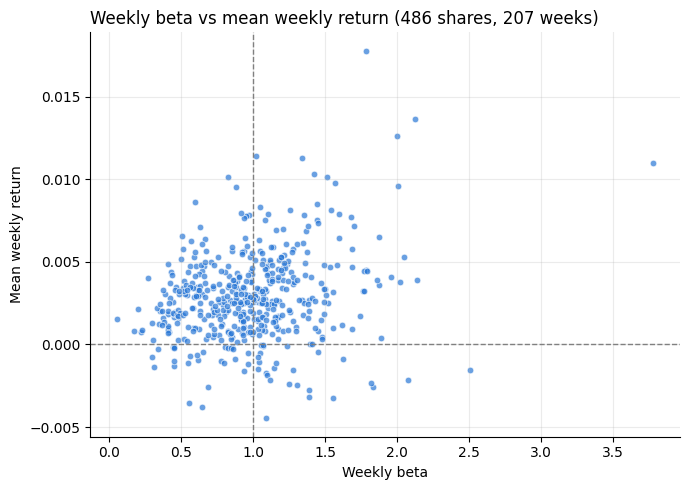

In [46]:
import matplotlib.pyplot as plt

# Scatter of beta vs mean weekly return; dashed lines at beta = 1 and zero return
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(rr["weekly_beta"], rr["mean_weekly_return"], s=22, color="#2a78d6",
           alpha=0.7, edgecolors="white", linewidths=0.6)
ax.axvline(1, color="grey", lw=1, ls="--"); ax.axhline(0, color="grey", lw=1, ls="--")
ax.set_xlabel("Weekly beta"); ax.set_ylabel("Mean weekly return")
ax.set_title(f"Weekly beta vs mean weekly return ({len(rr)} shares, {N_WEEKS} weeks)", loc="left")
ax.grid(alpha=0.25); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/1_3_beta_vs_return.png", dpi=150); plt.show()

# 1.4 Adapted RFM calculations
Event: volume > 2 × mean volume of the preceding 20 sessions (test day excluded).

## Common rules

### (a) Observation date
Final common completed trading date.

In [47]:
# Close and Volume for retained shares
close = close_w[retained]
vol = vol_w[retained]

# Observation date = last day on which every share has a price and volume
all_present = close.notna().all(axis=1) & vol.notna().all(axis=1)
OBS_DATE = all_present[all_present].index.max()
close, vol = close.loc[:OBS_DATE], vol.loc[:OBS_DATE]
print("Observation date:", OBS_DATE.date())

Observation date: 2024-12-31


### (b) Rolling 20-session threshold
`rolling(20).mean().shift(1)` per share and day; the first 20 days cannot be tested.

In [48]:
# Mean volume of the previous 20 sessions (shift(1) excludes the test day)
baseline = vol.rolling(window=20, min_periods=20).mean().shift(1)
threshold = 2 * baseline
# Event = volume more than twice the baseline
event = vol > threshold          # True = unusually high-volume day

print("Days that cannot be tested (no 20-day history):", int(baseline.iloc[:, 0].isna().sum()))
print("Zero baselines found:", int((baseline == 0).sum().sum()))

Days that cannot be tested (no 20-day history): 20
Zero baselines found: 0


### (c) Threshold cross-check

In [49]:
# Second method: shift first, then average - must give the same baseline
baseline_alt = vol.shift(1).rolling(window=20, min_periods=20).mean()
print("Largest difference between the two methods:", (baseline - baseline_alt).abs().max().max())
assert (baseline - baseline_alt).abs().max().max() < 1e-6, "baseline methods disagree"
print("PASS: threshold excludes the test day")

Largest difference between the two methods: 0.0
PASS: threshold excludes the test day


### (d) Latest 60 sessions

In [50]:
# Latest 60 trading sessions ending on the observation date
window = vol.index[-60:]
print("60-session window:", window[0].date(), "to", window[-1].date(), "| sessions:", len(window))
print("Window ends on observation date:", window[-1] == OBS_DATE)
print("Enough history before window (needs 20):", vol.index.get_loc(window[0]) >= 20)
# Window ends on the observation date and has at least 20 earlier sessions
assert window[-1] == OBS_DATE and len(window) == 60 and vol.index.get_loc(window[0]) >= 20
print("PASS: 60-session window and 20-session history confirmed")

60-session window: 2024-10-07 to 2024-12-31 | sessions: 60
Window ends on observation date: True
Enough history before window (needs 20): True
PASS: 60-session window and 20-session history confirmed


## 1.4.1 Recency (R)
Calendar days from the latest event to the observation date; missing (not zero) if there is no event.

In [51]:
# Date of each share's latest event
last_event = event.apply(lambda col: col[col].index.max())     # NaT if no event
# R = calendar days from the latest event to the observation date
recency = (OBS_DATE - last_event).dt.days

print("Shares with no qualifying event (R missing):", int(recency.isna().sum()))
print("Shares with an event on the observation date (R = 0):", int((recency == 0).sum()))

Shares with no qualifying event (R missing): 0
Shares with an event on the observation date (R = 0): 0


## 1.4.2 Frequency (F)
Event days within the latest 60 sessions.

In [52]:
# F = number of event days in the 60-session window
frequency = event.loc[window].sum()

print("F = 0 but an earlier event exists:", int(((frequency == 0) & recency.notna()).sum()))
frequency.describe()

F = 0 but an earlier event exists: 10


,0
count,486.000000
mean,2.989712
std,1.330800
min,0.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,8.000000


## 1.4.3 Monetary (M)
Σ Close × Volume over the latest 60 sessions, in USD: approximate traded value, not market capitalisation.

In [53]:
# M = sum of Close x Volume over the 60-session window (USD)
monetary = (close.loc[window] * vol.loc[window]).sum()

print(f"Median M: {monetary.median():,.0f} USD | max M: {monetary.max():,.0f} USD")
monetary.describe()

Median M: 16,683,821,505 USD | max M: 1,847,697,379,222 USD


,0
count,486.000000
mean,"39,404,191,889.207840"
std,"129,138,833,232.971680"
min,"1,297,482,617.047882"
25%,"10,195,173,392.270470"
50%,"16,683,821,504.623032"
75%,"32,276,893,043.872356"
max,"1,847,697,379,221.842773"


### RFM table

In [54]:
# R, F and M in one table
rfm = pd.DataFrame({"last_event_date": last_event, "R_days": recency,
                    "F_count": frequency, "M_usd": monetary})
rfm.head()

,last_event_date,R_days,F_count,M_usd
Ticker,,,,
A,2024-12-20,11,2,"14,001,795,716.048431"
AAPL,2024-12-20,11,2,"623,303,377,706.584229"
ABBV,2024-12-20,11,3,"68,370,537,641.661072"
ABNB,2024-12-20,11,3,"36,528,503,216.287994"
ABT,2024-12-20,11,1,"35,230,272,606.274414"


# 1.5 Metric interpretation and supporting evidence

## 1.5.1 Worked RFM example

In [55]:
# Use AAPL if it has an event in the window; otherwise the share with the most events
EX_RFM = EX if event.loc[window, EX].any() else event.loc[window].sum().idxmax()
print("Worked example share:", EX_RFM)

Worked example share: AAPL


In [56]:
# Daily volume, baseline, threshold and event flag for the example share
ex = pd.DataFrame({"close": close[EX_RFM], "volume": vol[EX_RFM], "baseline_20d": baseline[EX_RFM],
                   "threshold_2x": threshold[EX_RFM], "event": event[EX_RFM]}).loc[window]
# Daily traded value = Close x Volume
ex["traded_value_usd"] = ex["close"] * ex["volume"]
ex.to_csv("logs/worked_example_rfm.csv")

print("Share:", EX_RFM, "| Observation date:", OBS_DATE.date())
print("Busy days inside the 60-session window:")
# Show the event days only
ex[ex["event"]]

Share: AAPL | Observation date: 2024-12-31
Busy days inside the 60-session window:


,close,volume,baseline_20d,threshold_2x,event,traded_value_usd
Date,,,,,,
2024-11-25,232.869995,"90,152,800.000000","43,820,740.000000","87,641,480.000000",True,"20,993,882,095.800781"
2024-12-20,254.490005,"147,495,300.000000","45,004,605.000000","90,009,210.000000",True,"37,536,079,707.215881"


In [57]:
# Show how R, F and M are calculated for the example share
r = rfm.loc[EX_RFM]
if pd.notna(r.last_event_date):
    print(f"R: latest event {r.last_event_date.date()} -> {OBS_DATE.date()} = {r.R_days:.0f} calendar days")
else:
    print("R: no qualifying event -> missing (excluded from RFM clustering)")
print(f"F: {int(ex['event'].sum())} busy days in the window (table value {int(r.F_count)})")
print(f"M: sum of 60 daily traded values = ${ex['traded_value_usd'].sum():,.0f} (table value ${r.M_usd:,.0f})")

R: latest event 2024-12-20 -> 2024-12-31 = 11 calendar days
F: 2 busy days in the window (table value 2)
M: sum of 60 daily traded values = $623,303,377,707 (table value $623,303,377,707)


### Threshold hand check

In [58]:
# First event day of the example share
day = ex.index[ex["event"]][0] if ex["event"].any() else OBS_DATE
pos = vol.index.get_loc(day)
# The 20 sessions before that day, recalculated directly from raw volumes
prev20 = vol[EX_RFM].iloc[pos - 20:pos]

print("Test day:", day.date(), "| previous 20 sessions:", prev20.index[0].date(), "to", prev20.index[-1].date())
print(f"Hand mean: {prev20.mean():,.0f} | code baseline: {baseline.at[day, EX_RFM]:,.0f}")
print(f"Volume {vol.at[day, EX_RFM]:,.0f} > 2 x mean {2 * prev20.mean():,.0f}?", vol.at[day, EX_RFM] > 2 * prev20.mean())

Test day: 2024-11-25 | previous 20 sessions: 2024-10-28 to 2024-11-22
Hand mean: 43,820,740 | code baseline: 43,820,740
Volume 90,152,800 > 2 x mean 87,641,480? True


## 1.5.2 Market-wide vs company-specific events

In [59]:
# Number of shares with an event on each day of the window
events_per_day = event.loc[window].sum(axis=1)
print("Days in the window with the most busy shares:")
print(events_per_day.sort_values(ascending=False).head(5).to_string())

# Most common latest-event dates (these drive R)
print("\nMost common latest-event dates (drives R):")
print(rfm["last_event_date"].value_counts().head(5).to_string())

Days in the window with the most busy shares:
Date
2024-12-20    354
2024-11-06    156
2024-10-31     83
2024-11-25     76
2024-10-30     46

Most common latest-event dates (drives R):
last_event_date
2024-12-20    353
2024-11-25     17
2024-11-06     11
2024-11-01      6
2024-11-15      6


## 1.5.3 Feature table (one row per included share)

In [60]:
# Feature table: one row per retained share
features = rr.join(rfm)
features["n_weeks"] = n_weeks
features = features.join(sp500.set_index("yahoo_ticker")[["Security", "GICS Sector"]])
# Shares with a valid R can be used for RFM clustering
features["rfm_valid"] = features["R_days"].notna()
features.index.name = "Ticker"

# Save the feature table
features.to_csv("data/processed/feature_table.csv")
print("Shares in feature table:", len(features), "| valid for RFM clustering:", int(features.rfm_valid.sum()))
features.head()

Shares in feature table: 486 | valid for RFM clustering: 486


,mean_weekly_return,weekly_beta,last_event_date,R_days,F_count,M_usd,n_weeks,Security,GICS Sector,rfm_valid
Ticker,,,,,,,,,,
A,0.001121,1.074724,2024-12-20,11,2,"14,001,795,716.048431",207,Agilent Technologies,Health Care,True
AAPL,0.003930,1.174836,2024-12-20,11,2,"623,303,377,706.584229",207,Apple Inc.,Information Technology,True
ABBV,0.003749,0.425365,2024-12-20,11,3,"68,370,537,641.661072",207,AbbVie,Health Care,True
ABNB,0.001475,1.472709,2024-12-20,11,3,"36,528,503,216.287994",207,Airbnb,Consumer Discretionary,True
ABT,0.000971,0.583542,2024-12-20,11,1,"35,230,272,606.274414",207,Abbott Laboratories,Health Care,True


### Common valid share set
Used for all four Task 2 solutions.

In [61]:
# Common share set used for all four Task 2 solutions
common_set = features.index[features["rfm_valid"]]
pd.Series(common_set, name="Ticker").to_csv("data/processed/common_share_set.csv", index=False)
print("Common share set for both clusterings:", len(common_set))

Common share set for both clusterings: 486


## 1.5.4 Feature summaries

In [62]:
# Summary statistics and skew for the five features
cols = ["mean_weekly_return", "weekly_beta", "R_days", "F_count", "M_usd"]
feature_summary = features[cols].describe().T
feature_summary["skew"] = features[cols].skew()
feature_summary.to_csv("logs/feature_summary.csv")
feature_summary

,count,mean,std,min,25%,50%,75%,max,skew
mean_weekly_return,486.000000,0.002857,0.002652,-0.004468,0.001182,0.002619,0.004207,0.017772,0.867516
weekly_beta,486.000000,0.973695,0.407339,0.055454,0.666599,0.950610,1.179538,3.778560,1.103650
R_days,486.000000,20.407407,21.342438,4.000000,11.000000,11.000000,14.750000,222.000000,3.645784
F_count,486.000000,2.989712,1.330800,0.000000,2.000000,3.000000,4.000000,8.000000,0.424735
M_usd,486.000000,"39,404,191,889.207840","129,138,833,232.971680","1,297,482,617.047882","10,195,173,392.270470","16,683,821,504.623032","32,276,893,043.872356","1,847,697,379,221.842773",11.683797


### Feature distributions

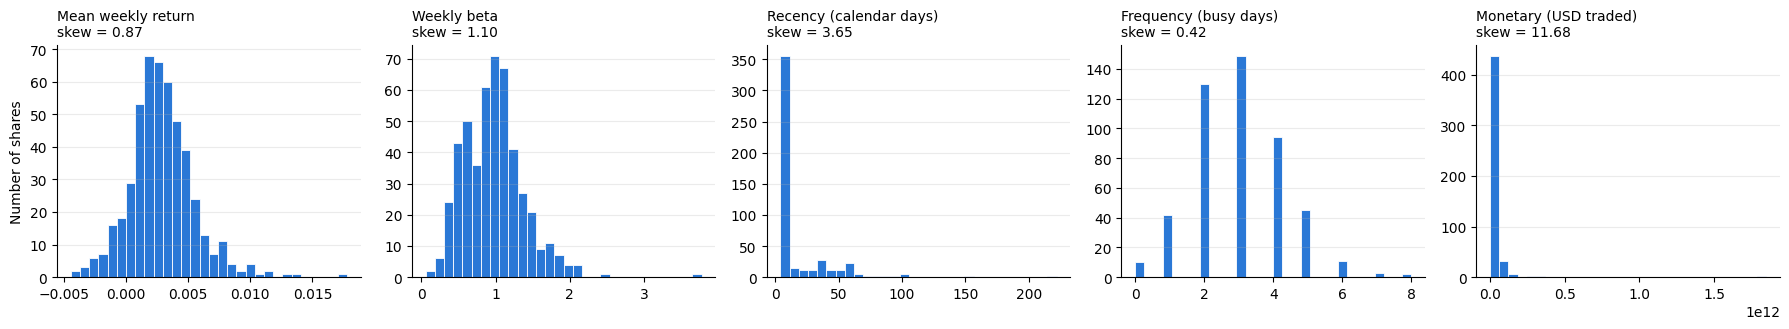

In [63]:
# Histogram of each feature with its skew
labels = {"mean_weekly_return": "Mean weekly return", "weekly_beta": "Weekly beta",
          "R_days": "Recency (calendar days)", "F_count": "Frequency (busy days)",
          "M_usd": "Monetary (USD traded)"}
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for ax, (col, name) in zip(axes, labels.items()):
    ax.hist(features[col].dropna(), bins=30, color="#2a78d6", edgecolor="white", linewidth=0.6)
    ax.set_title(f"{name}\nskew = {features[col].skew():.2f}", loc="left", fontsize=10)
    ax.grid(axis="y", alpha=0.25); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Number of shares")
plt.tight_layout(); plt.savefig("figures/1_5_feature_histograms.png", dpi=150); plt.show()

## 1.5.5 Inclusion and exclusion log

In [64]:
validation_reasons = excluded["reason"].to_dict()

# Final status and reason for every company in the Wikipedia list
def final_status(row):
    t = row["yahoo_ticker"]
    if row["status"] == "failed": return pd.Series(["excluded", "1.1 download failed"])
    if t in dupe_tickers: return pd.Series(["excluded", "1.2 conflicting duplicate rows"])
    if t in validation_reasons: return pd.Series(["excluded", "1.2 " + validation_reasons[t]])
    if not features.at[t, "rfm_valid"]: return pd.Series(["included; not in RFM clustering", "1.4 no qualifying event"])
    return pd.Series(["included", ""])

# Build and save the inclusion/exclusion log
inclusion_log = acq_log[["Symbol", "yahoo_ticker", "Security", "GICS Sector"]].copy()
inclusion_log[["final_status", "reason"]] = acq_log.apply(final_status, axis=1)
inclusion_log.to_csv("logs/inclusion_exclusion_log.csv", index=False)
inclusion_log["final_status"].value_counts()

,count
final_status,
included,486
excluded,17


### Rules summary
- **Inclusion:** complete Close, Adj Close and Volume; prices > 0; volume > 0.
- **Weeks:** W-FRI, last Adj Close, incomplete edge weeks removed.
- **Event:** volume > 2 × mean of the previous 20 sessions.
- **R, F, M:** observation date 31 Dec 2024; F and M over the latest 60 sessions.

## 1.5.6 Metric interpretation

In [65]:
# Key figures for the metric interpretation
s = features
print(f"Mean weekly return: median {s.mean_weekly_return.median():.4%}, range {s.mean_weekly_return.min():.4%} to {s.mean_weekly_return.max():.4%}, skew {s.mean_weekly_return.skew():.2f}")
print(f"Weekly beta:        median {s.weekly_beta.median():.2f}, range {s.weekly_beta.min():.2f} to {s.weekly_beta.max():.2f}, skew {s.weekly_beta.skew():.2f}")
print(f"R (days):           median {s.R_days.median():.0f}, range {s.R_days.min():.0f} to {s.R_days.max():.0f}, skew {s.R_days.skew():.2f}")
print(f"F (busy days):      median {s.F_count.median():.0f}, range {s.F_count.min():.0f} to {s.F_count.max():.0f}, skew {s.F_count.skew():.2f}")
print(f"M (USD):            median {s.M_usd.median():,.0f}, range {s.M_usd.min():,.0f} to {s.M_usd.max():,.0f}, skew {s.M_usd.skew():.2f}")
# Most common latest-event date
top_day = rfm["last_event_date"].value_counts()
print(f"Most common latest-event date: {top_day.index[0].date()} ({top_day.iloc[0]} of {len(rfm)} shares)")

Mean weekly return: median 0.2619%, range -0.4468% to 1.7772%, skew 0.87
Weekly beta:        median 0.95, range 0.06 to 3.78, skew 1.10
R (days):           median 11, range 4 to 222, skew 3.65
F (busy days):      median 3, range 0 to 8, skew 0.42
M (USD):            median 16,683,821,505, range 1,297,482,617 to 1,847,697,379,222, skew 11.68
Most common latest-event date: 2024-12-20 (353 of 486 shares)


- **Mean weekly return, beta:** past average return and market sensitivity over 207 weeks; estimates, not forecasts.
- **R, F:** timing and frequency of unusual volume. Many events are market-wide (1.5.2), and a spike does not show whether news was good or bad.
- **M:** traded value, largely driven by company size; a rough liquidity proxy only.
- **Distributions:** M heavily right-skewed; R concentrated at 11 days (20 Dec 2024); F small and roughly symmetric.
- High M does not imply high F, because events are relative to each share's own normal volume (e.g. NVDA: R = 222, F = 0).

## 1.5.7 Record key facts

In [66]:
# Add Task 1 key facts to the metadata file
metadata.update({
    "observation_date": str(OBS_DATE.date()),
    "aligned_weekly_observations": int(N_WEEKS),
    "first_return_week": str(gspc_ret.index[0].date()),
    "last_return_week": str(gspc_ret.index[-1].date()),
    "inclusion_rule": "valid Close, Adj Close, Volume on every benchmark trading day; prices > 0; volume > 0",
    "event_rule": "volume > 2 x mean of previous 20 sessions (excluding test day)",
    "rfm_window_sessions": 60,
    "shares_retained": len(retained),
    "shares_valid_for_rfm": int(features.rfm_valid.sum()),
})
with open("logs/acquisition_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
metadata

{'wikipedia_url': 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies',
 'wikipedia_retrieved_utc': '2026-11-23T11:34:41+00:00',
 'yahoo_retrieved_utc': '2026-11-23T11:36:38+00:00',
 'package': 'yfinance 1.8.0',
 'start': '2021-01-01',
 'end_exclusive': '2025-01-01',
 'auto_adjust': False,
 'benchmark': '^GSPC',
 'data_source': 'live',
 'tickers_requested': 503,
 'failed_downloads': ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR'],
 'observation_date': '2024-12-31',
 'aligned_weekly_observations': 207,
 'first_return_week': '2021-01-15',
 'last_return_week': '2024-12-27',
 'inclusion_rule': 'valid Close, Adj Close, Volume on every benchmark trading day; prices > 0; volume > 0',
 'event_rule': 'volume > 2 x mean of previous 20 sessions (excluding test day)',
 'rfm_window_sessions': 60,
 'shares_retained': 486,
 'shares_valid_for_rfm': 486}

# Task 2 — Stock segmentation and sensitivity analysis
Two separate matrices — risk & return (mean weekly return, beta) and trading activity (R, F, log1p M) — each clustered with Ward and K-Means on the common share set.

### Setup

In [67]:
# Scaling, clustering, evaluation and PCA tools
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# fixed colour order for clusters 1..8 (colour-blind-checked palette)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
K_RANGE = range(2, 9)          # brief: compare 2 to 8 clusters

# Common chart styling
def tidy(ax):
    ax.grid(alpha=0.25); ax.spines[["top", "right"]].set_visible(False)

# Label a silhouette score
def sil_quality(s):
    # Kaufman & Rousseeuw (1990) interpretation of the average silhouette
    if s > 0.70: return "strong"
    if s > 0.50: return "reasonable"
    if s > 0.25: return "weak"
    return "no substantial structure"

Silhouette bands (Kaufman & Rousseeuw, 1990): > 0.70 strong; 0.51–0.70 reasonable; 0.26–0.50 weak; ≤ 0.25 no substantial structure.

# 2.1 Feature preparation

## 2.1.1 Feature matrices

In [68]:
# Features for each matrix
rr_cols = ["mean_weekly_return", "weekly_beta"]
rfm_cols = ["R_days", "F_count", "log1p_M"]

# Common share set; log1p applied to Monetary
data = features.loc[common_set].copy()
data["log1p_M"] = np.log1p(data["M_usd"])          # brief: log1p applied to Monetary

# The two separate feature matrices
X_rr_raw = data[rr_cols]
X_rfm_raw = data[rfm_cols]
print("Shares in both matrices:", len(data))
print("Missing values:", int(X_rr_raw.isna().sum().sum() + X_rfm_raw.isna().sum().sum()))

Shares in both matrices: 486
Missing values: 0


## 2.1.2 Skew before and after log1p

In [69]:
# Skew of each feature before and after log1p
skew_table = pd.DataFrame({"raw_skew": data[["mean_weekly_return", "weekly_beta", "R_days", "F_count", "M_usd"]].skew()})
for col in ["R_days", "F_count", "M_usd"]:
    skew_table.loc[col, "log1p_skew"] = np.log1p(data[col]).skew()
skew_table.round(2)

,raw_skew,log1p_skew
mean_weekly_return,0.870000,NaN
weekly_beta,1.100000,NaN
R_days,3.650000,1.580000
F_count,0.420000,-0.930000
M_usd,11.680000,1.080000


## 2.1.3 Outliers (|z| > 3)
Inspected, not removed.

In [70]:
# z-score = distance from the mean in standard deviations
model_cols = rr_cols + rfm_cols
z = (data[model_cols] - data[model_cols].mean()) / data[model_cols].std()
print("Outliers per feature (|z| > 3):")
print((z.abs() > 3).sum().to_string())

# The most extreme shares across all features
extreme = z.abs().max(axis=1).sort_values(ascending=False).head(8).index
data.loc[extreme, ["Security", "GICS Sector"] + model_cols].round(4)

Outliers per feature (|z| > 3):
mean_weekly_return     6
weekly_beta            2
R_days                11
F_count                5
log1p_M                7


,Security,GICS Sector,mean_weekly_return,weekly_beta,R_days,F_count,log1p_M
Ticker,,,,,,,
NVDA,Nvidia,Information Technology,0.013600,2.126000,222,0,28.232800
CVNA,Carvana,Consumer Discretionary,0.011000,3.778600,36,3,24.370400
WEC,WEC Energy Group,Utilities,0.001400,0.384700,151,0,23.104400
SMCI,Supermicro,Information Technology,0.017800,1.783700,29,5,25.845300
TSLA,"Tesla, Inc.",Consumer Discretionary,0.005300,2.045800,50,5,28.245000
HRL,Hormel Foods,Consumer Staples,-0.000800,0.301100,102,0,22.198800
CB,Chubb Limited,Financials,0.003500,0.573100,102,0,23.951500
DUK,Duke Energy,Utilities,0.002000,0.353200,102,0,23.847700


## 2.1.4 Treatment of skewed variables
- **M:** log1p applied.
- **R:** kept in days; log1p (skew 3.65 → 1.58) cannot spread the 353 shares at R = 11.
- **Beta, mean return:** kept; extreme values are genuine shares.
- A minimum cluster size stops outliers forming their own cluster.

## 2.1.5 Standardisation
Separate `StandardScaler` for each matrix (mean 0, SD 1).

In [71]:
# Standardise each matrix separately (mean 0, standard deviation 1)
X_rr = StandardScaler().fit_transform(X_rr_raw)
X_rfm = StandardScaler().fit_transform(X_rfm_raw)

# Check: means are 0 and standard deviations are 1
print("Risk & return  - means:", X_rr.mean(axis=0).round(6), "| std:", X_rr.std(axis=0).round(3))
print("Trading activity - means:", X_rfm.mean(axis=0).round(6), "| std:", X_rfm.std(axis=0).round(3))

Risk & return  - means: [ 0. -0.] | std: [1. 1.]
Trading activity - means: [-0. -0. -0.] | std: [1. 1. 1.]


# 2.2 Agglomerative clustering (Ward)
Ward linkage, Euclidean distance, standardised features. Deterministic and needs no preset k, but merges are irreversible and it favours compact, similar-sized groups.

**k selection:** k = 2–8 compared on silhouette, merge gaps, sizes (minimum 10 shares) and profiles.

In [72]:
# Smallest acceptable cluster: 10 shares or 2% of the sample
MIN_SIZE = max(10, int(0.02 * len(data)))
print("Minimum feasible cluster size:", MIN_SIZE)

# Silhouette, quality label and cluster sizes for one solution
def evaluate_labels(X, labels):
    sizes = np.bincount(labels)[np.unique(labels)]
    s = silhouette_score(X, labels)
    return {"n_clusters": len(sizes), "silhouette": s, "quality": sil_quality(s),
            "min_size": int(sizes.min()), "sizes": sorted(sizes.tolist(), reverse=True)}

# Highest silhouette among solutions without clusters below the minimum size
def suggest_k(table):
    feasible = table[table["min_size"] >= MIN_SIZE]
    return int((feasible if len(feasible) else table)["silhouette"].idxmax())

Minimum feasible cluster size: 10


## 2.2.1 Linkage and dendrogram function

In [73]:
# Ward linkage with Euclidean distance on the standardised matrices
Z_rr = linkage(X_rr, method="ward", metric="euclidean")
Z_rfm = linkage(X_rfm, method="ward", metric="euclidean")

# Dendrogram of the last 30 merges, with a dashed line at the selected cut
def plot_dendrogram(Z, title, path, k=None):
    fig, ax = plt.subplots(figsize=(10, 4))
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, color_threshold=0, above_threshold_color="#52514e")
    if k:
        ax.axhline((Z[-k, 2] + Z[-(k - 1), 2]) / 2, color=PALETTE[1], ls="--", lw=1.5, label=f"cut for k = {k}")
        ax.legend(frameon=False)
    ax.set_title(title, loc="left"); ax.set_ylabel("Merge distance (Ward)"); ax.set_xlabel("Shares / merged groups")
    tidy(ax); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

## 2.2.2 Compare k = 2 … 8

In [74]:
# Evaluate Ward solutions for k = 2 to 8
def ward_table(Z, X):
    rows = {k: evaluate_labels(X, fcluster(Z, k, criterion="maxclust")) for k in K_RANGE}
    return pd.DataFrame(rows).T.rename_axis("k").infer_objects()

ward_rr_eval = ward_table(Z_rr, X_rr)
ward_rfm_eval = ward_table(Z_rfm, X_rfm)
# Save and print both tables
ward_rr_eval.to_csv("logs/ward_rr_evaluation.csv"); ward_rfm_eval.to_csv("logs/ward_rfm_evaluation.csv")
print("RISK & RETURN - Ward"); print(ward_rr_eval.round(3).to_string())
print("\nTRADING ACTIVITY - Ward"); print(ward_rfm_eval.round(3).to_string())

RISK & RETURN - Ward
   n_clusters  silhouette quality  min_size                             sizes
k                                                                            
2           2    0.339000    weak        92                         [394, 92]
3           3    0.274000    weak        92                    [230, 164, 92]
4           4    0.282000    weak        48                [182, 164, 92, 48]
5           5    0.304000    weak        48             [182, 98, 92, 66, 48]
6           6    0.320000    weak         5          [182, 98, 87, 66, 48, 5]
7           7    0.324000    weak         5      [160, 98, 87, 66, 48, 22, 5]
8           8    0.321000    weak         5  [160, 98, 66, 56, 48, 31, 22, 5]

TRADING ACTIVITY - Ward
   n_clusters  silhouette quality  min_size                              sizes
k                                                                             
2           2    0.368000    weak        82                          [404, 82]
3           3  

## 2.2.3 Merge-distance gaps

In [75]:
# Gap between the merge heights above and below each cut
def merge_gap_table(Z):
    rows = {}
    for k in K_RANGE:
        above, below = Z[-(k - 1), 2], Z[-k, 2]       # merge that would leave k-1 groups vs the one that made k
        rows[k] = {"merge_height_above_cut": above, "merge_height_below_cut": below,
                   "gap": above - below, "gap_ratio": above / below}
    return pd.DataFrame(rows).T.rename_axis("k")

# Merge gaps for both matrices
gap_rr, gap_rfm = merge_gap_table(Z_rr), merge_gap_table(Z_rfm)
gap_rr.to_csv("logs/ward_rr_merge_gaps.csv"); gap_rfm.to_csv("logs/ward_rfm_merge_gaps.csv")
print("RISK & RETURN - merge gaps"); print(gap_rr.round(3).to_string())
print("Largest gap at k =", int(gap_rr["gap"].idxmax()), "| silhouette suggests k =", suggest_k(ward_rr_eval))
print("\nTRADING ACTIVITY - merge gaps"); print(gap_rfm.round(3).to_string())
print("Largest gap at k =", int(gap_rfm["gap"].idxmax()), "| silhouette suggests k =", suggest_k(ward_rfm_eval))

RISK & RETURN - merge gaps
   merge_height_above_cut  merge_height_below_cut      gap  gap_ratio
k                                                                    
2               23.073000               18.803000 4.271000   1.227000
3               18.803000               14.210000 4.592000   1.323000
4               14.210000               12.669000 1.541000   1.122000
5               12.669000               11.601000 1.068000   1.092000
6               11.601000                8.342000 3.260000   1.391000
7                8.342000                8.308000 0.033000   1.004000
8                8.308000                5.929000 2.379000   1.401000
Largest gap at k = 3 | silhouette suggests k = 2

TRADING ACTIVITY - merge gaps
   merge_height_above_cut  merge_height_below_cut      gap  gap_ratio
k                                                                    
2               26.706000               22.985000 3.720000   1.162000
3               22.985000               15.843000 7.1

## 2.2.4 Candidate profiles (original units)

In [76]:
# Median (or mean) of each feature per cluster, with cluster sizes
def profile(labels, cols, stat="median"):
    df = data[cols].copy(); df["cluster"] = labels
    prof = df.groupby("cluster")[cols].agg(stat)
    prof.insert(0, "n_shares", df.groupby("cluster").size())
    return prof

# Profiles for the suggested k and its neighbours
def show_candidates(Z, cols, k_mid):
    for k in sorted({max(2, k_mid - 1), k_mid, min(8, k_mid + 1)}):
        print(f"\n--- k = {k} ---")
        print(profile(fcluster(Z, k, criterion="maxclust"), cols).round(4).to_string())

print("Suggested k (risk & return):", suggest_k(ward_rr_eval))
show_candidates(Z_rr, rr_cols, suggest_k(ward_rr_eval))

Suggested k (risk & return): 2

--- k = 2 ---
         n_shares  mean_weekly_return  weekly_beta
cluster                                           
1              92            0.005500     1.217700
2             394            0.002100     0.881700

--- k = 3 ---
         n_shares  mean_weekly_return  weekly_beta
cluster                                           
1              92            0.005500     1.217700
2             164            0.003300     0.577700
3             230            0.001700     1.038400


In [77]:
# Trading activity profiles in original units (M in USD)
rfm_profile_cols = ["R_days", "F_count", "M_usd"]
print("Suggested k (trading activity):", suggest_k(ward_rfm_eval))
show_candidates(Z_rfm, rfm_profile_cols, suggest_k(ward_rfm_eval))

Suggested k (trading activity): 2

--- k = 2 ---
         n_shares    R_days  F_count                 M_usd
cluster                                                   
1              82 54.500000 2.000000 17,849,026,950.297001
2             404 11.000000 3.000000 16,047,277,680.313499

--- k = 3 ---
         n_shares    R_days  F_count                 M_usd
cluster                                                   
1              82 54.500000 2.000000 17,849,026,950.297001
2             154 11.000000 3.000000 39,695,450,024.572800
3             250 11.000000 3.000000 11,177,612,626.543800


## 2.2.5 Selected Ward k
**k = 3 for both matrices.**
- Largest merge gap at k = 3 (risk & return 4.59; trading activity 7.14).
- Interpretable profiles; smallest groups 92 and 82.
- Lower silhouette than k = 2 accepted, as every k is in the weak band.

In [78]:
# Selected Ward cluster counts (reasons in 2.2.5)
K_WARD_RR = 3
K_WARD_RFM = 3

# Cut each Ward tree into the selected number of clusters
ward_rr = fcluster(Z_rr, K_WARD_RR, criterion="maxclust")
ward_rfm = fcluster(Z_rfm, K_WARD_RFM, criterion="maxclust")
print("Ward risk & return: k =", K_WARD_RR, "| sizes:", np.bincount(ward_rr)[1:].tolist())
print("Ward trading activity: k =", K_WARD_RFM, "| sizes:", np.bincount(ward_rfm)[1:].tolist())
print("Silhouette rule had suggested:", suggest_k(ward_rr_eval), "and", suggest_k(ward_rfm_eval))

Ward risk & return: k = 3 | sizes: [92, 164, 230]
Ward trading activity: k = 3 | sizes: [82, 154, 250]
Silhouette rule had suggested: 2 and 2


## 2.2.6 Dendrograms

### (a) Risk & return dendrogram

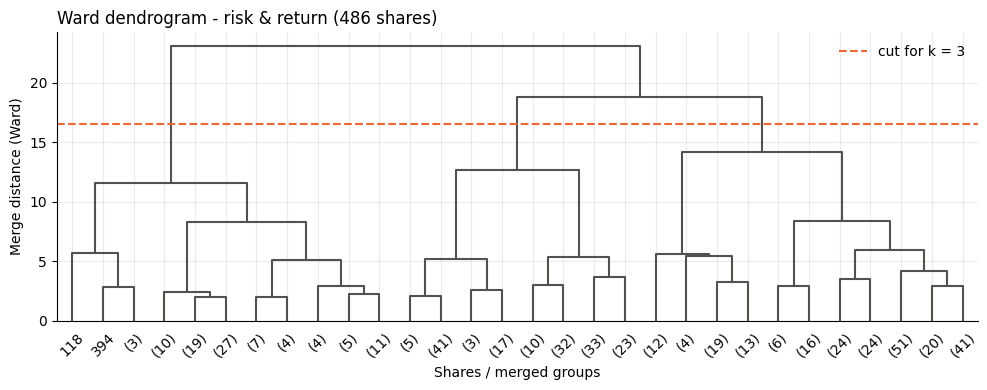

In [79]:
# Risk & return dendrogram
plot_dendrogram(Z_rr, f"Ward dendrogram - risk & return ({len(data)} shares)", "figures/2_2_dendrogram_rr.png", K_WARD_RR)

### (b) Trading activity dendrogram

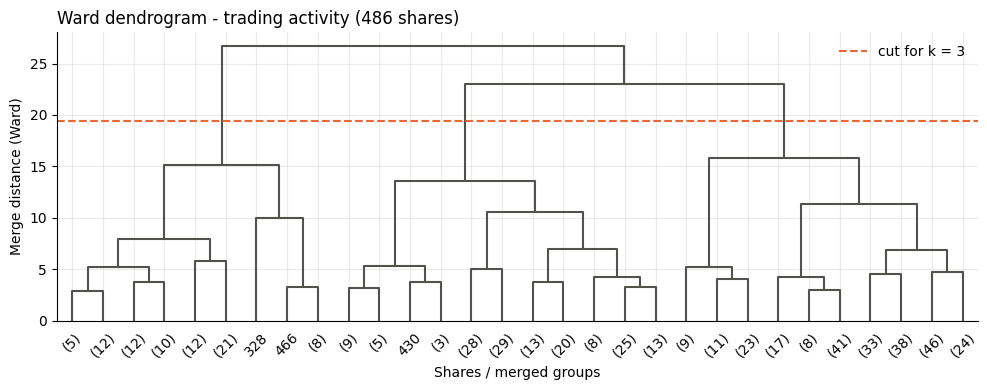

In [80]:
# Trading activity dendrogram
plot_dendrogram(Z_rfm, f"Ward dendrogram - trading activity ({len(data)} shares)", "figures/2_2_dendrogram_rfm.png", K_WARD_RFM)

## 2.2.7 Check: scipy vs scikit-learn

In [81]:
# Fit Ward again with scikit-learn and compare with scipy (ARI = 1 means identical)
for name, X, labels, k in [("risk & return", X_rr, ward_rr, K_WARD_RR), ("trading activity", X_rfm, ward_rfm, K_WARD_RFM)]:
    sk = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    print(f"{name}: ARI scipy vs scikit-learn = {adjusted_rand_score(labels, sk):.3f}")

risk & return: ARI scipy vs scikit-learn = 1.000
trading activity: ARI scipy vs scikit-learn = 1.000


# 2.3 K-Means clustering
Fixed seed (42) and 50 initialisations. Assumes compact, similar-variance clusters; sensitive to outliers and starting centres.

## 2.3.1 Compare k = 2 … 8

In [82]:
# Number of random starts for every K-Means run
N_INIT = 50

# Evaluate K-Means for k = 2 to 8 (fixed seed), including inertia
def kmeans_table(X):
    rows = {}
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X)
        rows[k] = {**evaluate_labels(X, km.labels_), "inertia": km.inertia_}
    return pd.DataFrame(rows).T.rename_axis("k").infer_objects()

km_rr_eval = kmeans_table(X_rr)
km_rfm_eval = kmeans_table(X_rfm)
# Save and print both tables
km_rr_eval.to_csv("logs/kmeans_rr_evaluation.csv"); km_rfm_eval.to_csv("logs/kmeans_rfm_evaluation.csv")
print("RISK & RETURN - K-Means"); print(km_rr_eval.round(3).to_string())
print("\nTRADING ACTIVITY - K-Means"); print(km_rfm_eval.round(3).to_string())

RISK & RETURN - K-Means
   n_clusters  silhouette quality  min_size                             sizes    inertia
k                                                                                       
2           2    0.387000    weak       143                        [343, 143] 621.634000
3           3    0.329000    weak       119                   [202, 165, 119] 461.179000
4           4    0.326000    weak        41               [160, 153, 132, 41] 371.571000
5           5    0.338000    weak        28           [165, 124, 114, 55, 28] 309.960000
6           6    0.326000    weak        20        [134, 115, 85, 76, 56, 20] 265.707000
7           7    0.329000    weak         5     [126, 105, 84, 78, 47, 41, 5] 227.239000
8           8    0.354000    weak         5  [135, 80, 78, 76, 43, 40, 29, 5] 194.249000

TRADING ACTIVITY - K-Means
   n_clusters  silhouette quality  min_size                              sizes      inertia
k                                                      

## 2.3.2 Diagnostics: silhouette and inertia
Elbow located with the knee (maximum-distance) method.

### (a) Elbow and diagnostic functions

In [83]:
# Elbow = point furthest from the straight line joining the first and last inertia values
def elbow_k(inertia):
    ks = np.array(list(inertia.index), dtype=float)
    y = inertia.values.astype(float)
    xn = (ks - ks.min()) / (ks.max() - ks.min())          # scale both axes to 0-1 so units do not matter
    yn = (y - y.min()) / (y.max() - y.min())
    # distance of each point from the line joining the first and last point
    dist = np.abs((yn[-1] - yn[0]) * xn - (xn[-1] - xn[0]) * yn + xn[-1] * yn[0] - yn[-1] * xn[0]) / np.hypot(yn[-1] - yn[0], xn[-1] - xn[0])
    return int(ks[dist.argmax()])

In [84]:
# Silhouette for both algorithms (left) and K-Means inertia with the elbow (right)
def diagnostics_plot(ward_eval, km_eval, title, path):
    ks = list(K_RANGE)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    a1.plot(ks, ward_eval["silhouette"], marker="o", lw=2, color=PALETTE[0], label="Ward")
    a1.plot(ks, km_eval["silhouette"], marker="s", lw=2, color=PALETTE[1], label="K-Means")
    a1.set_title(f"{title}: silhouette", loc="left"); a1.set_xlabel("k"); a1.legend(frameon=False)
    a2.plot(ks, km_eval["inertia"], marker="s", lw=2, color=PALETTE[1])
    e = elbow_k(km_eval["inertia"])
    a2.axvline(e, color="#52514e", ls="--", lw=1.2, label=f"elbow (knee method): k = {e}")
    a2.legend(frameon=False)
    a2.set_title(f"{title}: K-Means inertia", loc="left"); a2.set_xlabel("k")
    for a in (a1, a2): tidy(a)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

# Print the elbow and the silhouette suggestion for each matrix
for name, ev in [("Risk & return", km_rr_eval), ("Trading activity", km_rfm_eval)]:
    print(f"{name}: elbow k = {elbow_k(ev['inertia'])} | silhouette rule suggests k = {suggest_k(ev)}")

Risk & return: elbow k = 4 | silhouette rule suggests k = 2
Trading activity: elbow k = 4 | silhouette rule suggests k = 2


### (b) Risk & return: silhouette and inertia

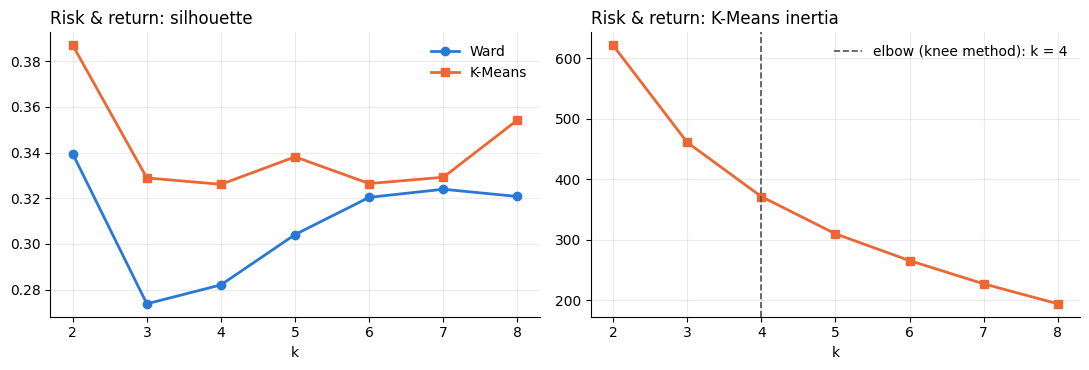

In [85]:
# Risk & return diagnostics
diagnostics_plot(ward_rr_eval, km_rr_eval, "Risk & return", "figures/2_3_diagnostics_rr.png")

### (c) Trading activity: silhouette and inertia

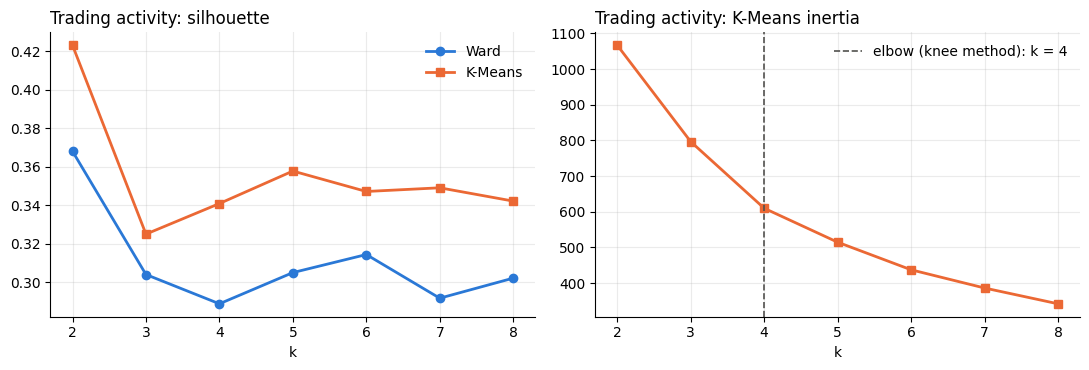

In [86]:
# Trading activity diagnostics
diagnostics_plot(ward_rfm_eval, km_rfm_eval, "Trading activity", "figures/2_3_diagnostics_rfm.png")

## 2.3.3 Selected K-Means k
- **Risk & return: k = 3** — matches Ward for a like-for-like comparison; k = 5 was less stable across starts.
- **Trading activity: k = 4** — inertia elbow; higher silhouette than k = 3 (0.341 vs 0.325); smallest group 61.

In [87]:
# Selected K-Means cluster counts (reasons in 2.3.3)
K_KM_RR = 3
K_KM_RFM = 4

# Final K-Means models with the fixed seed and 50 starts
km_rr_model = KMeans(n_clusters=K_KM_RR, n_init=N_INIT, random_state=SEED).fit(X_rr)
km_rfm_model = KMeans(n_clusters=K_KM_RFM, n_init=N_INIT, random_state=SEED).fit(X_rfm)
km_rr, km_rfm = km_rr_model.labels_ + 1, km_rfm_model.labels_ + 1      # number clusters from 1, like Ward
print("K-Means risk & return: k =", K_KM_RR, "| sizes:", np.bincount(km_rr)[1:].tolist())
print("K-Means trading activity: k =", K_KM_RFM, "| sizes:", np.bincount(km_rfm)[1:].tolist())
print("Silhouette rule had suggested:", suggest_k(km_rr_eval), "and", suggest_k(km_rfm_eval))

K-Means risk & return: k = 3 | sizes: [119, 202, 165]
K-Means trading activity: k = 4 | sizes: [212, 122, 61, 91]
Silhouette rule had suggested: 2 and 2


## 2.3.4 Per-cluster silhouette
A cluster is flagged if its mean silhouette is negative or most of its shares are negative.

In [88]:
# The four selected solutions
selected = {
    f"Ward - risk & return (k={K_WARD_RR})": (X_rr, ward_rr),
    f"K-Means - risk & return (k={K_KM_RR})": (X_rr, km_rr),
    f"Ward - trading activity (k={K_WARD_RFM})": (X_rfm, ward_rfm),
    f"K-Means - trading activity (k={K_KM_RFM})": (X_rfm, km_rfm),
}
# Mean silhouette and % of negative values for every cluster
rows = []
for name, (X, labels) in selected.items():
    sv = silhouette_samples(X, labels)
    for c in sorted(np.unique(labels)):
        v = sv[labels == c]
        rows.append({"solution": name, "cluster": c, "n_shares": len(v),
                     "mean_silhouette": v.mean(), "share_negative_%": 100 * (v < 0).mean(),
                     "flag": "CHECK" if (v.mean() < 0 or (v < 0).mean() > 0.5) else "ok"})
# Save and print the table
per_cluster_sil = pd.DataFrame(rows)
per_cluster_sil.to_csv("logs/per_cluster_silhouette.csv", index=False)
print(per_cluster_sil.round(3).to_string(index=False))

                        solution  cluster  n_shares  mean_silhouette  share_negative_% flag
      Ward - risk & return (k=3)        1        92         0.319000          3.261000   ok
      Ward - risk & return (k=3)        2       164         0.313000         10.366000   ok
      Ward - risk & return (k=3)        3       230         0.228000         17.391000   ok
   K-Means - risk & return (k=3)        1       119         0.274000          4.202000   ok
   K-Means - risk & return (k=3)        2       202         0.384000          0.000000   ok
   K-Means - risk & return (k=3)        3       165         0.301000          0.606000   ok
   Ward - trading activity (k=3)        1        82         0.184000         25.610000   ok
   Ward - trading activity (k=3)        2       154         0.247000          7.792000   ok
   Ward - trading activity (k=3)        3       250         0.378000          0.000000   ok
K-Means - trading activity (k=4)        1       212         0.374000          0.

### Silhouette plots

In [89]:
# Silhouette plot: one bar per share, grouped by cluster; dashed line = average
def silhouette_panels(names, path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, name in zip(axes, names):
        X, labels = selected[name]
        sv = silhouette_samples(X, labels)
        y0 = 0
        for c in sorted(np.unique(labels)):
            v = np.sort(sv[labels == c])
            ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=PALETTE[c - 1], alpha=0.85)
            ax.text(-0.05, y0 + len(v) / 2, f"C{c}", ha="right", va="center", fontsize=8)
            y0 += len(v) + 5                                   # small gap between clusters
        ax.axvline(sv.mean(), color="#52514e", ls="--", lw=1.2)
        ax.axvline(0, color="#52514e", lw=0.8)
        ax.set_title(name, loc="left", fontsize=10); ax.set_yticks([]); ax.set_xlabel("Silhouette value"); tidy(ax)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

# Names of the four solutions in order
names = list(selected)

#### Risk & return: Ward and K-Means

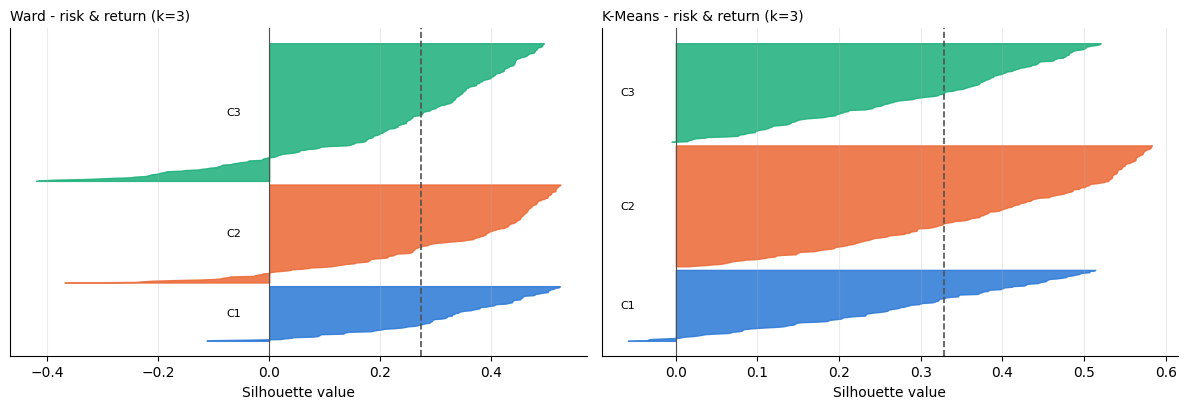

In [90]:
# Risk & return: Ward and K-Means
silhouette_panels(names[:2], "figures/2_3_silhouette_rr.png")

#### Trading activity: Ward and K-Means

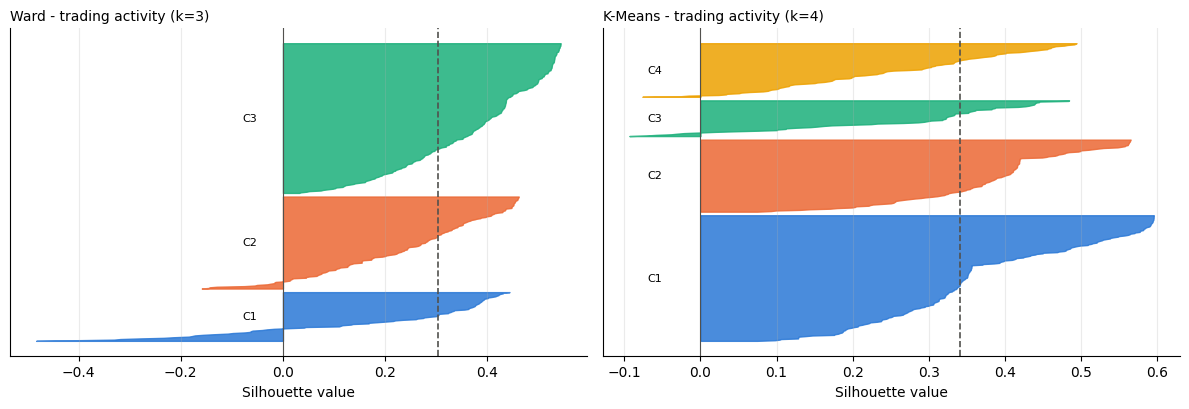

In [91]:
# Trading activity: Ward and K-Means
silhouette_panels(names[2:], "figures/2_3_silhouette_rfm.png")

## 2.3.5 Experiment: number of initialisations
1 vs 50 starts across 10 seeds.

In [92]:
# Compare 1 start vs 50 starts over 10 seeds: inertia range and agreement with the selected solution
def init_experiment(X, k, base_labels):
    rows = []
    for n_init in (1, N_INIT):
        for seed in range(10):
            km = KMeans(n_clusters=k, n_init=n_init, random_state=seed).fit(X)
            rows.append({"n_init": n_init, "seed": seed, "inertia": km.inertia_,
                         "ARI_vs_selected": adjusted_rand_score(base_labels, km.labels_)})
    return pd.DataFrame(rows).groupby("n_init")[["inertia", "ARI_vs_selected"]].agg(["min", "max"])

# Run the experiment for both matrices
print("Risk & return:"); print(init_experiment(X_rr, K_KM_RR, km_rr).round(4).to_string())
print("\nTrading activity:"); print(init_experiment(X_rfm, K_KM_RFM, km_rfm).round(4).to_string())

Risk & return:
          inertia            ARI_vs_selected         
              min        max             min      max
n_init                                               
1      461.178700 461.202200        0.993100 1.000000
50     461.178700 461.178700        1.000000 1.000000

Trading activity:
          inertia            ARI_vs_selected         
              min        max             min      max
n_init                                               
1      609.832500 728.519700        0.346000 1.000000
50     609.832500 609.832500        1.000000 1.000000


# 2.4 Cluster profiles and algorithm comparison
Clusters renumbered for readability (risk & return by median beta; trading activity by median R, then median M). Labels are arbitrary.

In [93]:
# Renumber clusters in a meaningful order (labels are arbitrary)
def relabel(labels, order_values, tiebreak=None):
    """Renumber clusters 1..k by the cluster median of order_values; ties broken by the median of tiebreak."""
    df = pd.DataFrame({"label": labels, "a": order_values, "b": 0 if tiebreak is None else tiebreak})
    order = df.groupby("label")[["a", "b"]].median().sort_values(["a", "b"]).index
    new_number = {old: n + 1 for n, old in enumerate(order)}
    return np.array([new_number[l] for l in labels])

# Risk & return by median beta; trading activity by median R, ties by higher median M
ward_rr = relabel(ward_rr, data["weekly_beta"].values)
km_rr = relabel(km_rr, data["weekly_beta"].values)
ward_rfm = relabel(ward_rfm, data["R_days"].values, -data["M_usd"].values)
km_rfm = relabel(km_rfm, data["R_days"].values, -data["M_usd"].values)
print("Relabelled: risk & return by median beta; trading activity by median R, ties by higher median M first.")

Relabelled: risk & return by median beta; trading activity by median R, ties by higher median M first.


## 2.4.1 Profiles in original units (median and mean)

In [94]:
# The four solutions and the features used to describe them
solutions = {
    "Ward - risk & return": (ward_rr, rr_cols),
    "K-Means - risk & return": (km_rr, rr_cols),
    "Ward - trading activity": (ward_rfm, rfm_profile_cols),
    "K-Means - trading activity": (km_rfm, rfm_profile_cols),
}
profiles = {}
# Median and mean profiles in original units; saved per solution
for name, (labels, cols) in solutions.items():
    med, mean = profile(labels, cols, "median"), profile(labels, cols, "mean")
    both = med[["n_shares"]].join(med[cols].add_suffix(" (median)")).join(mean[cols].add_suffix(" (mean)"))
    profiles[name] = both
    both.to_csv(f"logs/profile_{name.replace(' - ', '_').replace(' ', '_').replace('&', 'and')}.csv")
    print(f"\n=== {name} ===")
    print(both.round(4).to_string())


=== Ward - risk & return ===
         n_shares  mean_weekly_return (median)  weekly_beta (median)  mean_weekly_return (mean)  weekly_beta (mean)
cluster                                                                                                            
1             164                     0.003300              0.577700                   0.002900            0.601200
2             230                     0.001700              1.038400                   0.001500            1.109600
3              92                     0.005500              1.217700                   0.006300            1.298100

=== K-Means - risk & return ===
         n_shares  mean_weekly_return (median)  weekly_beta (median)  mean_weekly_return (mean)  weekly_beta (mean)
cluster                                                                                                            
1             202                     0.002600              0.621500                   0.002600            0.630800
2        

## 2.4.2 Snake plots
Mean standardised feature value per cluster.

In [95]:
# Standardised data, labels and feature names for each solution
snake = {
    f"Ward - risk & return (k={K_WARD_RR})": (X_rr, ward_rr, ["mean return", "beta"]),
    f"K-Means - risk & return (k={K_KM_RR})": (X_rr, km_rr, ["mean return", "beta"]),
    f"Ward - trading activity (k={K_WARD_RFM})": (X_rfm, ward_rfm, ["R (days)", "F (count)", "log1p(M)"]),
    f"K-Means - trading activity (k={K_KM_RFM})": (X_rfm, km_rfm, ["R (days)", "F (count)", "log1p(M)"]),
}

# Snake plot: mean standardised value of each feature per cluster
def snake_panels(names, path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
    for ax, name in zip(axes, names):
        X, labels, feat = snake[name]
        means = pd.DataFrame(X, columns=feat).groupby(labels).mean()
        for c, row in means.iterrows():
            ax.plot(feat, row.values, marker="o", markersize=8, lw=2, color=PALETTE[c - 1],
                    label=f"Cluster {c} (n={(labels == c).sum()})")
        ax.axhline(0, color="#52514e", lw=0.8)
        ax.set_title(name, loc="left", fontsize=10); ax.legend(frameon=False, fontsize=8); tidy(ax)
    axes[0].set_ylabel("Mean standardised value")
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

snake_names = list(snake)

#### Risk & return

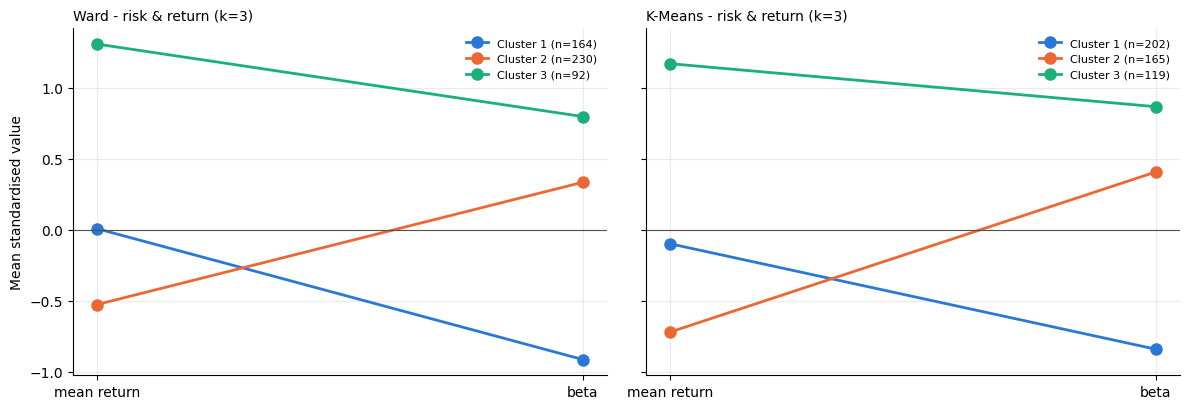

In [96]:
# Risk & return snake plots
snake_panels(snake_names[:2], "figures/2_4_snake_rr.png")

#### Trading activity

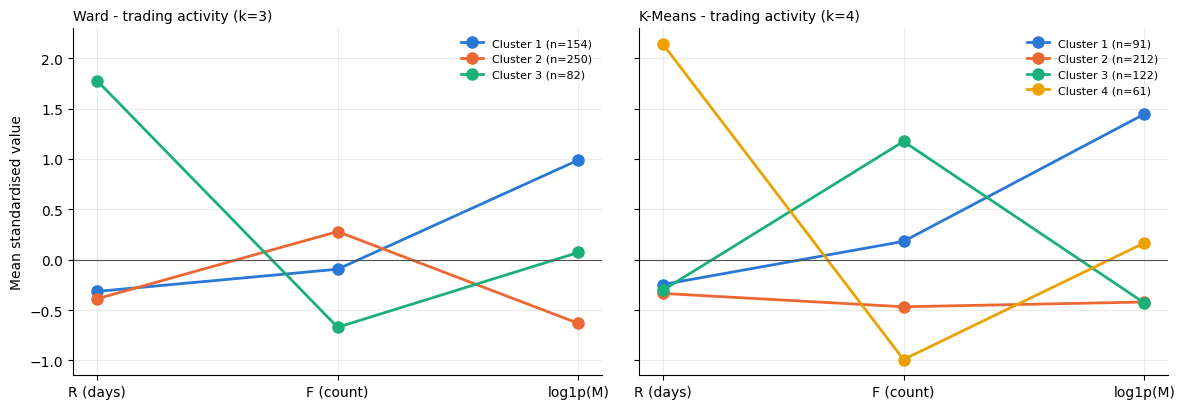

In [97]:
# Trading activity snake plots
snake_panels(snake_names[2:], "figures/2_4_snake_rfm.png")

## 2.4.3 Risk & return: 2-D view
Two features, so no dimensionality reduction.

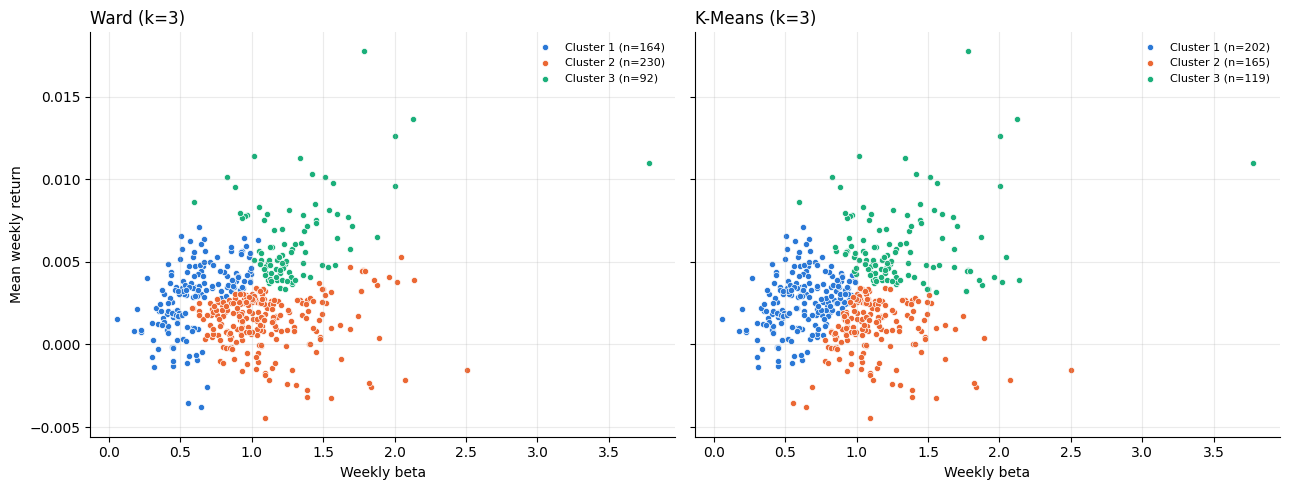

In [98]:
# Scatter plot coloured by cluster
def cluster_scatter(ax, x, y, labels, title):
    for c in sorted(np.unique(labels)):
        m = labels == c
        ax.scatter(x[m], y[m], s=20, color=PALETTE[c - 1], edgecolors="white", linewidths=0.5,
                   label=f"Cluster {c} (n={m.sum()})")
    ax.set_title(title, loc="left"); ax.legend(frameon=False, fontsize=8); tidy(ax)

# Risk & return clusters on the real beta and return axes
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, labels, name in [(axes[0], ward_rr, f"Ward (k={K_WARD_RR})"), (axes[1], km_rr, f"K-Means (k={K_KM_RR})")]:
    cluster_scatter(ax, data["weekly_beta"].values, data["mean_weekly_return"].values, labels, name)
    ax.set_xlabel("Weekly beta")
axes[0].set_ylabel("Mean weekly return")
plt.tight_layout(); plt.savefig("figures/2_4_clusters_rr.png", dpi=150); plt.show()

## 2.4.4 Trading activity: 2-D view (PCA)
PCA is used for display only; clustering used all three features.

In [99]:
# PCA reduces the three activity features to two axes for plotting only
pca = PCA(n_components=2, random_state=SEED).fit(X_rfm)
pcs = pca.transform(X_rfm)
# Variance explained and what each axis is made of (loadings)
print("Variance explained by PC1, PC2:", pca.explained_variance_ratio_.round(3),
      "| total:", round(pca.explained_variance_ratio_.sum(), 3))
print(pd.DataFrame(pca.components_, columns=rfm_cols, index=["PC1", "PC2"]).round(3).to_string())

Variance explained by PC1, PC2: [0.458 0.336] | total: 0.794
      R_days   F_count  log1p_M
PC1 0.711000 -0.650000 0.268000
PC2 0.023000  0.402000 0.915000


#### PCA chart

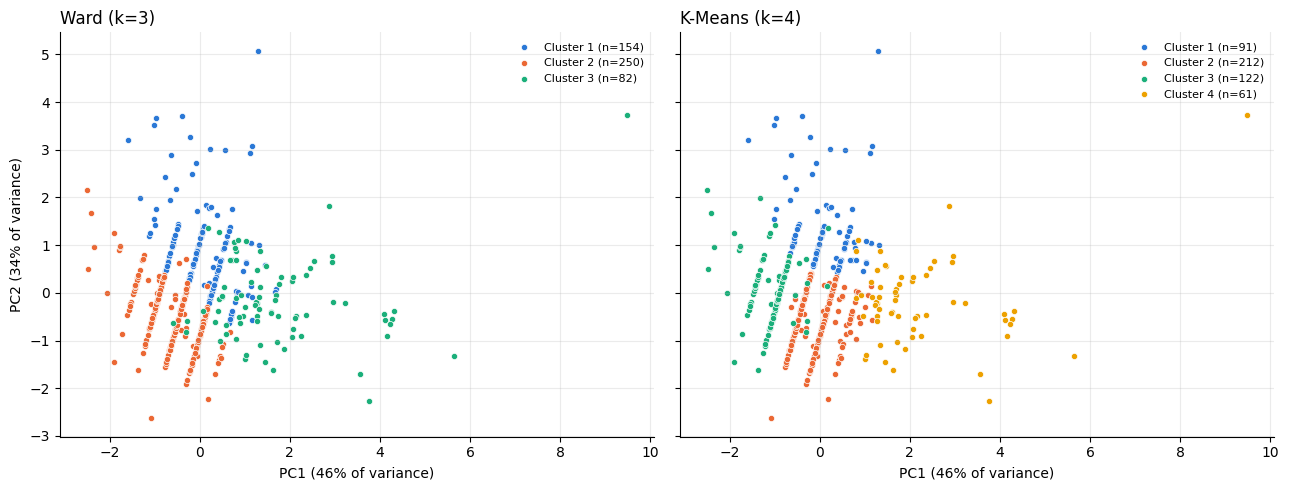

In [100]:
# Activity clusters on the two PCA axes
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, labels, name in [(axes[0], ward_rfm, f"Ward (k={K_WARD_RFM})"), (axes[1], km_rfm, f"K-Means (k={K_KM_RFM})")]:
    cluster_scatter(ax, pcs[:, 0], pcs[:, 1], labels, name)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
plt.tight_layout(); plt.savefig("figures/2_4_clusters_rfm_pca.png", dpi=150); plt.show()

## 2.4.5 Ward vs K-Means agreement (ARI)

In [101]:
# ARI and cross-table between Ward and K-Means for each matrix
for name, a, b in [("Risk & return", ward_rr, km_rr), ("Trading activity", ward_rfm, km_rfm)]:
    print(f"\n{name}: ARI Ward vs K-Means = {adjusted_rand_score(a, b):.3f}")
    print(pd.crosstab(pd.Series(a, name="Ward"), pd.Series(b, name="K-Means")).to_string())


Risk & return: ARI Ward vs K-Means = 0.516
K-Means    1    2   3
Ward                 
1        148    3  13
2         54  160  16
3          0    2  90

Trading activity: ARI Ward vs K-Means = 0.318
K-Means   1    2    3   4
Ward                     
1        84   52   14   4
2         0  146  104   0
3         7   14    4  57


## 2.4.6 Save cluster assignments

In [102]:
# Cluster assignments for the four baseline solutions
assignments = data[["Security", "GICS Sector"]].copy()
assignments["ward_risk_return"] = ward_rr
assignments["kmeans_risk_return"] = km_rr
assignments["ward_trading_activity"] = ward_rfm
assignments["kmeans_trading_activity"] = km_rfm
# Save the assignments
assignments.to_csv("data/processed/cluster_assignments.csv")
assignments.head()

,Security,GICS Sector,ward_risk_return,kmeans_risk_return,ward_trading_activity,kmeans_trading_activity
Ticker,,,,,,
A,Agilent Technologies,Health Care,2,2,2,2
AAPL,Apple Inc.,Information Technology,3,3,1,1
ABBV,AbbVie,Health Care,1,1,1,1
ABNB,Airbnb,Consumer Discretionary,2,2,1,1
ABT,Abbott Laboratories,Health Care,1,1,1,2


# 2.5 RFM sensitivity and correlated inputs

## 2.5.1 Correlation analysis
Correlated features add overlapping weight to Euclidean distance even after scaling; correlation alone does not prove dominance.

In [103]:
# Pearson (linear) and Spearman (rank) correlations among R, F and log1p(M)
corr_pearson = data[rfm_cols].corr(method="pearson")
corr_spearman = data[rfm_cols].corr(method="spearman")
corr_pearson.to_csv("logs/rfm_correlation_pearson.csv"); corr_spearman.to_csv("logs/rfm_correlation_spearman.csv")
print("Pearson:"); print(corr_pearson.round(3).to_string())
print("\nSpearman:"); print(corr_spearman.round(3).to_string())

Pearson:
           R_days   F_count  log1p_M
R_days   1.000000 -0.346000 0.152000
F_count -0.346000  1.000000 0.013000
log1p_M  0.152000  0.013000 1.000000

Spearman:
           R_days   F_count   log1p_M
R_days   1.000000 -0.196000  0.137000
F_count -0.196000  1.000000 -0.048000
log1p_M  0.137000 -0.048000  1.000000


## 2.5.2 Removal of Monetary
Ward on R and F only: same shares, same k, re-standardised; compared by ARI and traded-value profiles.

In [104]:
# R and F only, standardised again
X_rf = StandardScaler().fit_transform(data[["R_days", "F_count"]])       # standardised afresh
# Ward on the reduced matrix with the same k and the same shares
Z_rf = linkage(X_rf, method="ward", metric="euclidean")
ward_rf = relabel(fcluster(Z_rf, K_WARD_RFM, criterion="maxclust"), data["R_days"].values, -data["M_usd"].values)

# Agreement with the full RFM solution
ari_rf = adjusted_rand_score(ward_rfm, ward_rf)
print(f"Same shares: {len(X_rf)} | same k: {K_WARD_RFM}")
print(f"ARI full RFM vs R+F only: {ari_rf:.3f}")
print(pd.crosstab(pd.Series(ward_rfm, name="Full RFM"), pd.Series(ward_rf, name="R+F only")).to_string())

Same shares: 486 | same k: 3
ARI full RFM vs R+F only: 0.291
R+F only   1    2   3
Full RFM             
1         59   86   9
2         66  183   1
3          0    3  79


In [105]:
# Median R, F and traded value (USD bn) per cluster
def m_profile(labels):
    df = data[["R_days", "F_count", "M_usd"]].copy(); df["cluster"] = labels
    out = df.groupby("cluster").agg(n_shares=("M_usd", "size"), median_R=("R_days", "median"),
                                    median_F=("F_count", "median"), median_M_usd=("M_usd", "median"))
    out["median_M_bn"] = out.pop("median_M_usd") / 1e9
    return out

# Compare traded value profiles with and without M
print("Full RFM clusters:"); print(m_profile(ward_rfm).round(2).to_string())
print("\nR+F only clusters:"); print(m_profile(ward_rf).round(2).to_string())

Full RFM clusters:
         n_shares  median_R  median_F  median_M_bn
cluster                                           
1             154 11.000000  3.000000    39.700000
2             250 11.000000  3.000000    11.180000
3              82 54.500000  2.000000    17.850000

R+F only clusters:
         n_shares  median_R  median_F  median_M_bn
cluster                                           
1             125 11.000000  2.000000    17.700000
2             272 11.000000  4.000000    14.860000
3              89 54.000000  2.000000    20.850000


### Traded value by cluster

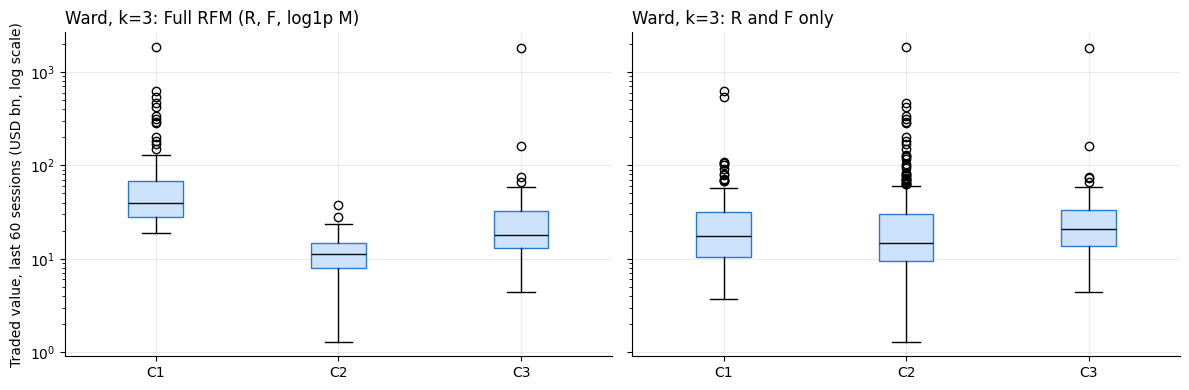

In [106]:
# Traded value per cluster (log scale), with and without M
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, labels, name in [(axes[0], ward_rfm, "Full RFM (R, F, log1p M)"), (axes[1], ward_rf, "R and F only")]:
    groups = [data["M_usd"].values[labels == c] / 1e9 for c in sorted(np.unique(labels))]
    ax.boxplot(groups, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", color="#2a78d6"), medianprops=dict(color="#0b0b0b"))
    ax.set_xticks(range(1, len(groups) + 1), [f"C{c}" for c in sorted(np.unique(labels))])
    ax.set_yscale("log"); ax.set_title(f"Ward, k={K_WARD_RFM}: {name}", loc="left"); tidy(ax)
axes[0].set_ylabel("Traded value, last 60 sessions (USD bn, log scale)")
plt.tight_layout(); plt.savefig("figures/2_5_traded_value_by_cluster.png", dpi=150); plt.show()

### Save the sensitivity assignment

In [107]:
# Add the sensitivity solution to the saved assignments
assignments["ward_RF_only_sensitivity"] = ward_rf
assignments.to_csv("data/processed/cluster_assignments.csv")
print("Columns saved:", list(assignments.columns))

Columns saved: ['Security', 'GICS Sector', 'ward_risk_return', 'kmeans_risk_return', 'ward_trading_activity', 'kmeans_trading_activity', 'ward_RF_only_sensitivity']


## 2.5.3 Experiment: effect of k
Key comparisons repeated at k = 2, 3 and 4.

In [108]:
# Key comparisons for one value of k
def at_k(k):
    w_rr, w_rfm = fcluster(Z_rr, k, criterion="maxclust"), fcluster(Z_rfm, k, criterion="maxclust")
    w_rf = fcluster(Z_rf, k, criterion="maxclust")
    k_rr = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit_predict(X_rr)
    k_rfm = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit_predict(X_rfm)
    return {
        "Ward RR silhouette": silhouette_score(X_rr, w_rr),
        "K-Means RR silhouette": silhouette_score(X_rr, k_rr),
        "Ward RFM silhouette": silhouette_score(X_rfm, w_rfm),
        "K-Means RFM silhouette": silhouette_score(X_rfm, k_rfm),
        "Ward RR sizes": sorted(np.bincount(w_rr)[1:].tolist(), reverse=True),
        "Ward RFM sizes": sorted(np.bincount(w_rfm)[1:].tolist(), reverse=True),
        "ARI Ward vs K-Means (RR)": adjusted_rand_score(w_rr, k_rr),
        "ARI Ward vs K-Means (RFM)": adjusted_rand_score(w_rfm, k_rfm),
        "ARI full RFM vs R+F only (Ward)": adjusted_rand_score(w_rfm, w_rf),
    }

# Repeat for k = 2, 3 and 4 and save
k_experiment = pd.DataFrame({f"k = {k}": at_k(k) for k in (2, 3, 4)})
k_experiment.to_csv("logs/k_experiment.csv")
k_experiment

,k = 2,k = 3,k = 4
Ward RR silhouette,0.339485,0.273834,0.282115
K-Means RR silhouette,0.386950,0.328907,0.326103
Ward RFM silhouette,0.368024,0.303979,0.288765
K-Means RFM silhouette,0.423122,0.324976,0.340867
Ward RR sizes,"[394, 92]","[230, 164, 92]","[182, 164, 92, 48]"
Ward RFM sizes,"[404, 82]","[250, 154, 82]","[207, 154, 82, 43]"
ARI Ward vs K-Means (RR),0.597555,0.516386,0.265143
ARI Ward vs K-Means (RFM),0.699819,0.833854,0.342970
ARI full RFM vs R+F only (Ward),0.873471,0.291151,0.202641


### Traded value profiles at k = 3

In [109]:
# Traded value profiles at k = 3, with and without M
w_rfm3 = relabel(fcluster(Z_rfm, 3, criterion="maxclust"), data["R_days"].values, -data["M_usd"].values)
w_rf3 = relabel(fcluster(Z_rf, 3, criterion="maxclust"), data["R_days"].values, -data["M_usd"].values)
print("Full RFM, k = 3:"); print(m_profile(w_rfm3).round(2).to_string())
print("\nR+F only, k = 3:"); print(m_profile(w_rf3).round(2).to_string())

Full RFM, k = 3:
         n_shares  median_R  median_F  median_M_bn
cluster                                           
1             154 11.000000  3.000000    39.700000
2             250 11.000000  3.000000    11.180000
3              82 54.500000  2.000000    17.850000

R+F only, k = 3:
         n_shares  median_R  median_F  median_M_bn
cluster                                           
1             125 11.000000  2.000000    17.700000
2             272 11.000000  4.000000    14.860000
3              89 54.000000  2.000000    20.850000


### Ward risk & return profiles at k = 3

In [110]:
# Ward risk & return profiles at k = 3
print(profile(relabel(fcluster(Z_rr, 3, criterion="maxclust"), data["weekly_beta"].values), rr_cols).round(4).to_string())

         n_shares  mean_weekly_return  weekly_beta
cluster                                           
1             164            0.003300     0.577700
2             230            0.001700     1.038400
3              92            0.005500     1.217700


**Result:** at k = 2, removing M barely changes membership (ARI 0.87); at k = 3 it changes substantially (ARI 0.29). With M, recently active shares split by traded value; without M, by Frequency. M mainly separates liquidity and size.

## 2.6 Record Task 2 decisions

In [111]:
# Add Task 2 decisions and results to the metadata file
metadata.update({
    "task2_common_shares": len(data),
    "min_feasible_cluster_size": MIN_SIZE,
    "k_ward_risk_return": K_WARD_RR, "k_kmeans_risk_return": K_KM_RR,
    "k_ward_trading_activity": K_WARD_RFM, "k_kmeans_trading_activity": K_KM_RFM,
    "kmeans_n_init": N_INIT, "random_seed": SEED,
    "ari_ward_vs_kmeans_rr": round(adjusted_rand_score(ward_rr, km_rr), 4),
    "ari_ward_vs_kmeans_rfm": round(adjusted_rand_score(ward_rfm, km_rfm), 4),
    "ari_full_rfm_vs_rf_only": round(ari_rf, 4),
    "largest_merge_gap_k_rr": int(gap_rr["gap"].idxmax()), "largest_merge_gap_k_rfm": int(gap_rfm["gap"].idxmax()),
    "elbow_k_rr": elbow_k(km_rr_eval["inertia"]), "elbow_k_rfm": elbow_k(km_rfm_eval["inertia"]),
    "clusters_flagged_by_silhouette": int((per_cluster_sil["flag"] == "CHECK").sum()),
})
with open("logs/acquisition_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
{k: v for k, v in metadata.items() if k.startswith(("k_", "ari", "task2", "min_", "kmeans", "largest", "elbow", "clusters_"))}

{'task2_common_shares': 486,
 'min_feasible_cluster_size': 10,
 'k_ward_risk_return': 3,
 'k_kmeans_risk_return': 3,
 'k_ward_trading_activity': 3,
 'k_kmeans_trading_activity': 4,
 'kmeans_n_init': 50,
 'ari_ward_vs_kmeans_rr': 0.5164,
 'ari_ward_vs_kmeans_rfm': 0.318,
 'ari_full_rfm_vs_rf_only': 0.2912,
 'largest_merge_gap_k_rr': 3,
 'largest_merge_gap_k_rfm': 3,
 'elbow_k_rr': 4,
 'elbow_k_rfm': 4,
 'clusters_flagged_by_silhouette': 0}

# Task 3 — Business intelligence and critical review
Evidence for 3.1 and 3.2, based on the selected Ward solutions (K-Means agreement reported alongside).

# 3.1 Data mart design
Star schema, built in SQLite.

| Table | Grain |
|---|---|
| `fact_daily_share` | share × trading day |
| `fact_weekly_return` | share × week |
| `fact_share_features` | share × calculation run |
| `dim_date`, `dim_share`, `dim_sector`, `dim_benchmark` | one row per member |
| `dim_run` | one row per calculation run (provenance) |

## 3.1.1 Dimension tables

### (a) Date dimension

In [112]:
import sqlite3

# Identifier for this calculation run
RUN_ID = "run_" + metadata["yahoo_retrieved_utc"][:10].replace("-", "")

# Date dimension: one row per trading day
dim_date = pd.DataFrame({"date": trading_days})
dim_date["date_key"] = dim_date["date"].dt.strftime("%Y%m%d").astype(int)
dim_date["year"] = dim_date["date"].dt.year
dim_date["quarter"] = dim_date["date"].dt.quarter
dim_date["month"] = dim_date["date"].dt.month
dim_date["day_of_week"] = dim_date["date"].dt.day_name()
# Friday of the week each day belongs to
dim_date["week_ending"] = dim_date["date"] + pd.to_timedelta((4 - dim_date["date"].dt.weekday) % 7, unit="D")   # Friday of that week
# Flags for the observation date and the RFM window
dim_date["is_observation_date"] = dim_date["date"] == OBS_DATE
dim_date["in_rfm_window"] = dim_date["date"].isin(window)
print("Date rows:", len(dim_date), "| RFM-window days:", int(dim_date.in_rfm_window.sum()))
dim_date.tail(3)

Date rows: 1005 | RFM-window days: 60


,date,date_key,year,quarter,month,day_of_week,week_ending,is_observation_date,in_rfm_window
1002,2024-12-27,20241227,2024,4,12,Friday,2024-12-27,False,True
1003,2024-12-30,20241230,2024,4,12,Monday,2025-01-03,False,True
1004,2024-12-31,20241231,2024,4,12,Tuesday,2025-01-03,True,True


### (b) Sector, share and benchmark dimensions
`dim_share` includes excluded shares with their reasons.

In [113]:
# Sector dimension
dim_sector = (sp500[["GICS Sector"]].drop_duplicates().sort_values("GICS Sector")
              .reset_index(drop=True).rename(columns={"GICS Sector": "gics_sector"}))
dim_sector.insert(0, "sector_key", range(1, len(dim_sector) + 1))
sector_key = dim_sector.set_index("gics_sector")["sector_key"]

# Share dimension: all 503 companies with their inclusion status and reason
dim_share = (inclusion_log.rename(columns={"yahoo_ticker": "ticker", "Symbol": "wikipedia_symbol",
                                           "Security": "security", "GICS Sector": "gics_sector"})
             .merge(sp500[["yahoo_ticker", "GICS Sub-Industry", "Date added"]]
                    .rename(columns={"yahoo_ticker": "ticker", "GICS Sub-Industry": "gics_sub_industry",
                                     "Date added": "date_added_to_index"}), on="ticker"))
dim_share["sector_key"] = dim_share["gics_sector"].map(sector_key)

# Benchmark dimension
dim_benchmark = pd.DataFrame([{"benchmark_key": 1, "symbol": BENCHMARK, "name": "S&P 500 index",
                               "price_basis": "price index (Adj Close = Close, dividends excluded)"}])
print("Sectors:", len(dim_sector), "| shares:", len(dim_share), "| benchmarks:", len(dim_benchmark))
dim_share["final_status"].value_counts()

Sectors: 11 | shares: 503 | benchmarks: 1


,count
final_status,
included,486
excluded,17


### (c) Run dimension (provenance)

In [114]:
# Run dimension: sources, retrieval times, versions and settings (provenance)
dim_run = pd.DataFrame([{
    "run_id": RUN_ID,
    "notebook": "CWK1_RFM_Stock_Segmentation.ipynb",
    "wikipedia_url": metadata["wikipedia_url"],
    "wikipedia_retrieved_utc": metadata["wikipedia_retrieved_utc"],
    "yahoo_retrieved_utc": metadata["yahoo_retrieved_utc"],
    "data_source": metadata["data_source"],
    "package_versions": json.dumps(versions),
    "study_start": START, "study_end_exclusive": END,
    "observation_date": str(OBS_DATE.date()),
    "weekly_rule": "W-FRI, last Adj Close, incomplete edge weeks removed",
    "event_rule": "volume > 2 x mean of previous 20 sessions",
    "baseline_sessions": 20, "rfm_window_sessions": 60,
    "k_ward_rr": K_WARD_RR, "k_kmeans_rr": K_KM_RR, "k_ward_rfm": K_WARD_RFM, "k_kmeans_rfm": K_KM_RFM,
    "kmeans_n_init": N_INIT, "random_seed": SEED,
}])
dim_run.T

,0
run_id,run_20261123
notebook,CWK1_RFM_Stock_Segmentation.ipynb
wikipedia_url,https://en.wikipedia.org/wiki/List_of_S%26P_50...
wikipedia_retrieved_utc,2026-11-23T11:34:41+00:00
yahoo_retrieved_utc,2026-11-23T11:36:38+00:00
data_source,live
package_versions,"{""pandas"": ""2.2.3"", ""numpy"": ""2.4.6"", ""yfinanc..."
study_start,2021-01-01
study_end_exclusive,2025-01-01
observation_date,2024-12-31


## 3.1.2 Fact tables

### (a) Daily fact

In [115]:
# Wide table (days x shares) -> one row per share per day
def long_table(wide_df, name):
    return wide_df.stack().rename(name)

# Daily fact: prices, volume, baseline, event flag and daily return
fact_daily = pd.concat([
    long_table(close_w[retained], "close"), long_table(adj_w[retained], "adj_close"),
    long_table(vol_w[retained], "volume"), long_table(baseline, "baseline_20d"),
    long_table(event.astype(int), "high_volume_event"), long_table(adj_w[retained].pct_change(fill_method=None), "daily_adj_return"),
], axis=1).reset_index()
fact_daily.columns = ["date", "ticker"] + list(fact_daily.columns[2:])
# Add traded value and the keys that link to the dimensions
fact_daily["traded_value_usd"] = fact_daily["close"] * fact_daily["volume"]
fact_daily["date_key"] = fact_daily["date"].dt.strftime("%Y%m%d").astype(int)
fact_daily["sector_key"] = fact_daily["ticker"].map(features["GICS Sector"]).map(sector_key)
fact_daily["benchmark_key"], fact_daily["run_id"] = 1, RUN_ID
fact_daily = fact_daily.drop(columns="date")
print("Daily fact rows:", len(fact_daily), "=", len(retained), "shares x", len(trading_days), "days ->",
      len(fact_daily) == len(retained) * len(trading_days))

Daily fact rows: 488430 = 486 shares x 1005 days -> True


### (b) Weekly fact

In [116]:
# Weekly fact: share and benchmark weekly returns
fact_weekly = weekly_ret.stack().rename("share_weekly_return").reset_index()
fact_weekly.columns = ["week_ending", "ticker", "share_weekly_return"]
fact_weekly["benchmark_weekly_return"] = fact_weekly["week_ending"].map(gspc_ret)
fact_weekly["week_key"] = fact_weekly["week_ending"].dt.strftime("%Y%m%d").astype(int)
fact_weekly["benchmark_key"], fact_weekly["run_id"] = 1, RUN_ID
fact_weekly = fact_weekly.drop(columns="week_ending")
print("Weekly fact rows:", len(fact_weekly), "=", len(retained), "x", N_WEEKS)

Weekly fact rows: 100602 = 486 x 207


### (c) Feature fact

In [117]:
# Feature fact: features and cluster assignments for each share in this run
fact_features = (data[["mean_weekly_return", "weekly_beta", "n_weeks", "R_days", "F_count", "M_usd", "log1p_M"]]
                 .join(assignments.drop(columns=["Security", "GICS Sector"])).reset_index()
                 .rename(columns={"Ticker": "ticker"}))
fact_features["sector_key"] = fact_features["ticker"].map(features["GICS Sector"]).map(sector_key)
fact_features["observation_date_key"] = int(OBS_DATE.strftime("%Y%m%d"))
fact_features["run_id"] = RUN_ID
fact_features.head(3)

,ticker,mean_weekly_return,weekly_beta,n_weeks,R_days,F_count,M_usd,log1p_M,ward_risk_return,kmeans_risk_return,ward_trading_activity,kmeans_trading_activity,ward_RF_only_sensitivity,sector_key,observation_date_key,run_id
0,A,0.001121,1.074724,207,11,2,"14,001,795,716.048431",23.362451,2,2,2,2,1,6,20241231,run_20261123
1,AAPL,0.003930,1.174836,207,11,2,"623,303,377,706.584229",27.158299,3,3,1,1,1,8,20241231,run_20261123
2,ABBV,0.003749,0.425365,207,11,3,"68,370,537,641.661072",24.948208,1,1,1,1,2,6,20241231,run_20261123


## 3.1.3 Save and query the data mart

In [118]:
os.makedirs("data/mart", exist_ok=True)
# Rebuild the SQLite data mart
mart_path = "data/mart/cwk1_data_mart.db"
if os.path.exists(mart_path):
    os.remove(mart_path)                         # rebuild from scratch each run

# Write all tables and count their rows
with sqlite3.connect(mart_path) as con:
    tables = {"dim_date": dim_date.assign(date=dim_date["date"].dt.date.astype(str),
                                          week_ending=dim_date["week_ending"].dt.date.astype(str)),
              "dim_share": dim_share, "dim_sector": dim_sector, "dim_benchmark": dim_benchmark, "dim_run": dim_run,
              "fact_daily_share": fact_daily, "fact_weekly_return": fact_weekly, "fact_share_features": fact_features}
    for name, df in tables.items():
        df.to_sql(name, con, index=False)
    counts = {name: con.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0] for name in tables}
pd.Series(counts, name="rows")

,rows
dim_date,1005
dim_share,503
dim_sector,11
dim_benchmark,1
dim_run,1
fact_daily_share,488430
fact_weekly_return,100602
fact_share_features,486


In [119]:
# Analyst query: average risk and activity by sector
query_sector = """
SELECT s.gics_sector, COUNT(*) AS shares,
       ROUND(AVG(f.weekly_beta), 2) AS avg_beta,
       ROUND(AVG(f.R_days), 1) AS avg_R_days,
       ROUND(AVG(f.F_count), 1) AS avg_F,
       ROUND(SUM(f.M_usd) / 1e9, 1) AS total_M_bn
FROM fact_share_features f JOIN dim_sector s ON f.sector_key = s.sector_key
GROUP BY s.gics_sector ORDER BY avg_beta DESC
"""
with sqlite3.connect(mart_path) as con:
    print("Analyst view: risk and activity by sector")
    display(pd.read_sql(query_sector, con))

Analyst view: risk and activity by sector


,gics_sector,shares,avg_beta,avg_R_days,avg_F,total_M_bn
0,Information Technology,74,1.360000,26.000000,3.000000,"6,390.700000"
1,Consumer Discretionary,47,1.220000,21.100000,2.800000,"3,478.700000"
2,Industrials,78,1.020000,16.000000,3.200000,"1,597.600000"
3,Financials,74,0.980000,18.200000,2.800000,"1,923.800000"
4,Materials,23,0.970000,26.800000,2.700000,399.500000
5,Real Estate,30,0.910000,11.000000,3.100000,353.300000
6,Communication Services,20,0.870000,18.500000,3.800000,"1,430.700000"
7,Health Care,58,0.810000,19.900000,3.300000,"1,737.800000"
8,Energy,20,0.760000,15.700000,2.300000,563.400000
9,Utilities,30,0.560000,29.600000,2.800000,426.200000


In [120]:
# Monitoring query: days with the most busy shares in the RFM window
query_monitor = """
SELECT d.date, SUM(f.high_volume_event) AS shares_with_busy_day
FROM fact_daily_share f JOIN dim_date d ON f.date_key = d.date_key
WHERE d.in_rfm_window = 1
GROUP BY d.date ORDER BY shares_with_busy_day DESC LIMIT 5
"""
with sqlite3.connect(mart_path) as con:
    print("Monitoring view: busiest days in the RFM window")
    display(pd.read_sql(query_monitor, con))

Monitoring view: busiest days in the RFM window


,date,shares_with_busy_day
0,2024-12-20,354
1,2024-11-06,156
2,2024-10-31,83
3,2024-11-25,76
4,2024-10-30,46


## 3.1.4 Star schema diagram

In [121]:
# Draw one table box with its fields; returns its centre for drawing links
def box(ax, x, y, title, fields, colour):
    h = 0.055 * (len(fields) + 1)
    ax.add_patch(plt.Rectangle((x, y - h), 0.26, h, facecolor="white", edgecolor=colour, lw=1.6))
    ax.add_patch(plt.Rectangle((x, y - 0.055), 0.26, 0.055, facecolor=colour, edgecolor=colour))
    ax.text(x + 0.01, y - 0.028, title, va="center", color="white", fontsize=9, weight="bold")
    for j, f in enumerate(fields):
        ax.text(x + 0.01, y - 0.055 * (j + 1.5), f, va="center", fontsize=7.5)
    return (x + 0.13, y - h / 2)

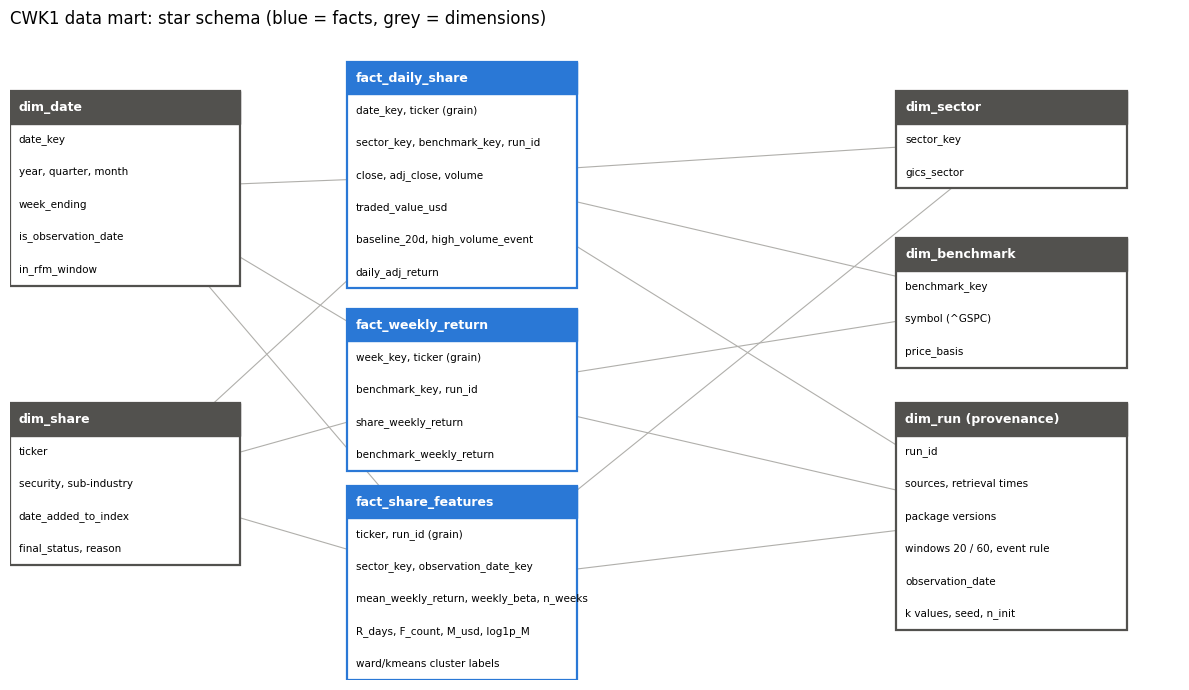

In [122]:
# Colours for fact and dimension tables
FACT, DIM = "#2a78d6", "#52514e"
fig, ax = plt.subplots(figsize=(12, 7)); ax.set_xlim(0, 1.32); ax.set_ylim(-0.05, 1.05); ax.axis("off")
# Fact tables in the middle
facts = {
    "daily": box(ax, 0.38, 1.00, "fact_daily_share", ["date_key, ticker (grain)", "sector_key, benchmark_key, run_id",
             "close, adj_close, volume", "traded_value_usd", "baseline_20d, high_volume_event", "daily_adj_return"], FACT),
    "weekly": box(ax, 0.38, 0.58, "fact_weekly_return", ["week_key, ticker (grain)", "benchmark_key, run_id",
              "share_weekly_return", "benchmark_weekly_return"], FACT),
    "features": box(ax, 0.38, 0.28, "fact_share_features", ["ticker, run_id (grain)", "sector_key, observation_date_key",
                "mean_weekly_return, weekly_beta, n_weeks", "R_days, F_count, M_usd, log1p_M", "ward/kmeans cluster labels"], FACT),
}
# Dimension tables around them
dims = {
    "date": box(ax, 0.00, 0.95, "dim_date", ["date_key", "year, quarter, month", "week_ending", "is_observation_date", "in_rfm_window"], DIM),
    "share": box(ax, 0.00, 0.42, "dim_share", ["ticker", "security, sub-industry", "date_added_to_index", "final_status, reason"], DIM),
    "sector": box(ax, 1.00, 0.95, "dim_sector", ["sector_key", "gics_sector"], DIM),
    "bench": box(ax, 1.00, 0.70, "dim_benchmark", ["benchmark_key", "symbol (^GSPC)", "price_basis"], DIM),
    "run": box(ax, 1.00, 0.42, "dim_run (provenance)", ["run_id", "sources, retrieval times", "package versions",
           "windows 20 / 60, event rule", "observation_date", "k values, seed, n_init"], DIM),
}
# Lines for the keys joining facts to dimensions
links = [("daily", "date"), ("daily", "share"), ("daily", "sector"), ("daily", "bench"), ("daily", "run"),
         ("weekly", "date"), ("weekly", "share"), ("weekly", "bench"), ("weekly", "run"),
         ("features", "share"), ("features", "sector"), ("features", "run"), ("features", "date")]
for f, d in links:
    (x1, y1), (x2, y2) = facts[f], dims[d]
    ax.plot([x1, x2], [y1, y2], color="#b0afab", lw=0.8, zorder=0)
ax.set_title("CWK1 data mart: star schema (blue = facts, grey = dimensions)", loc="left")
plt.tight_layout(); plt.savefig("figures/3_1_star_schema.png", dpi=150); plt.show()

# 3.2 Review of results
## 3.2.1 Risk & return clusters vs trading-activity clusters

### (a) Cross-table and ARI

In [123]:
# Cross-table of risk & return clusters against trading activity clusters
rr_vs_rfm = pd.crosstab(pd.Series(ward_rr, index=data.index, name="Risk & return (Ward)"),
                        pd.Series(ward_rfm, index=data.index, name="Trading activity (Ward)"), margins=True)
rr_vs_rfm.to_csv("logs/3_2_rr_vs_rfm_crosstab.csv")
# ARI near 0 = the two segmentations are unrelated
print(f"ARI Ward risk & return vs Ward trading activity: {adjusted_rand_score(ward_rr, ward_rfm):.3f}")
print(f"ARI K-Means risk & return vs K-Means trading activity: {adjusted_rand_score(km_rr, km_rfm):.3f}")
rr_vs_rfm

ARI Ward risk & return vs Ward trading activity: 0.024
ARI K-Means risk & return vs K-Means trading activity: 0.012


Trading activity (Ward),1,2,3,All
Risk & return (Ward),,,,
1,58,80,26,164
2,59,134,37,230
3,37,36,19,92
All,154,250,82,486


### (b) Heatmap (row percentages)

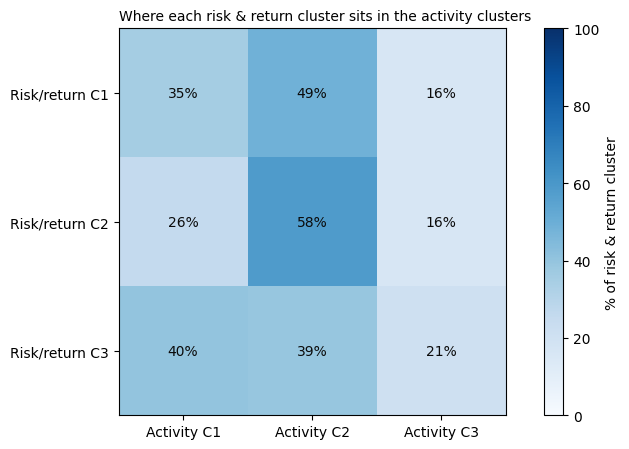

In [124]:
# Heatmap of the cross-table as row percentages
pct = pd.crosstab(ward_rr, ward_rfm, normalize="index") * 100
fig, ax = plt.subplots(figsize=(5 + K_WARD_RFM, 1.6 + K_WARD_RR))
im = ax.imshow(pct.values, cmap="Blues", vmin=0, vmax=100)
for r in range(pct.shape[0]):
    for c in range(pct.shape[1]):
        ax.text(c, r, f"{pct.values[r, c]:.0f}%", ha="center", va="center",
                color="white" if pct.values[r, c] > 60 else "#0b0b0b")
ax.set_xticks(range(pct.shape[1]), [f"Activity C{c}" for c in pct.columns])
ax.set_yticks(range(pct.shape[0]), [f"Risk/return C{r}" for r in pct.index])
ax.set_title("Where each risk & return cluster sits in the activity clusters", loc="left", fontsize=10)
plt.colorbar(im, ax=ax, label="% of risk & return cluster"); plt.tight_layout()
plt.savefig("figures/3_2_rr_vs_rfm_heatmap.png", dpi=150); plt.show()

### (c) Cross-profiles (original units)

In [125]:
# Describe each segmentation with all five features (medians, M in USD bn)
cross_cols = ["mean_weekly_return", "weekly_beta", "R_days", "F_count", "M_usd"]
cross_profiles = {}
for name, labels in [("Risk & return clusters (Ward)", ward_rr), ("Trading activity clusters (Ward)", ward_rfm)]:
    prof = profile(labels, cross_cols)
    prof["M_usd"] = prof["M_usd"] / 1e9
    prof = prof.rename(columns={"M_usd": "M_bn_usd"})
    cross_profiles[name] = prof
    print(f"\n=== {name}: medians ===")
    print(prof.round(4).to_string())


=== Risk & return clusters (Ward): medians ===
         n_shares  mean_weekly_return  weekly_beta    R_days  F_count  M_bn_usd
cluster                                                                        
1             164            0.003300     0.577700 11.000000 3.000000 17.649400
2             230            0.001700     1.038400 11.000000 3.000000 14.111400
3              92            0.005500     1.217700 11.000000 3.000000 24.184100

=== Trading activity clusters (Ward): medians ===
         n_shares  mean_weekly_return  weekly_beta    R_days  F_count  M_bn_usd
cluster                                                                        
1             154            0.003300     0.988600 11.000000 3.000000 39.695500
2             250            0.002500     0.927400 11.000000 3.000000 11.177600
3              82            0.002400     1.046600 54.500000 2.000000 17.849000


### (d) Sector composition
Lift = sector share in cluster ÷ sector share overall.

In [126]:
# Sector % of each cluster, and lift = cluster % / overall %
def sector_tables(labels):
    sector = data["GICS Sector"]
    pct = pd.crosstab(sector, pd.Series(labels, index=data.index, name="cluster"), normalize="columns") * 100
    overall = sector.value_counts(normalize=True) * 100
    lift = pct.div(overall, axis=0)
    return pct, lift

# Sector tables for both Ward segmentations
sec_rr_pct, sec_rr_lift = sector_tables(ward_rr)
sec_rfm_pct, sec_rfm_lift = sector_tables(ward_rfm)
sec_rr_pct.to_csv("logs/3_2_sector_pct_rr.csv"); sec_rfm_pct.to_csv("logs/3_2_sector_pct_rfm.csv")
print("Risk & return clusters — % of cluster | lift"); print(sec_rr_pct.round(1).join(sec_rr_lift.round(2), rsuffix=" lift").to_string())

Risk & return clusters — % of cluster | lift
cluster                        1         2         3   1 lift   2 lift   3 lift
GICS Sector                                                                    
Communication Services  4.900000  3.000000  5.400000 1.190000 0.740000 1.320000
Consumer Discretionary  5.500000 11.700000 12.000000 0.570000 1.210000 1.240000
Consumer Staples       16.500000  2.200000  0.000000 2.500000 0.330000 0.000000
Energy                  9.800000  0.000000  4.300000 2.370000 0.000000 1.060000
Financials             18.300000 13.500000 14.100000 1.200000 0.890000 0.930000
Health Care            16.500000 12.600000  2.200000 1.380000 1.060000 0.180000
Industrials             7.900000 19.100000 22.800000 0.490000 1.190000 1.420000
Information Technology  1.200000 18.700000 31.500000 0.080000 1.230000 2.070000
Materials               2.400000  7.000000  3.300000 0.520000 1.470000 0.690000
Real Estate             2.400000 10.000000  3.300000 0.400000 1.620000 0.53

In [127]:
# Trading activity sector table
print("Trading activity clusters — % of cluster | lift")
print(sec_rfm_pct.round(1).join(sec_rfm_lift.round(2), rsuffix=" lift").to_string())

Trading activity clusters — % of cluster | lift
cluster                        1         2         3   1 lift   2 lift   3 lift
GICS Sector                                                                    
Communication Services  5.800000  2.800000  4.900000 1.420000 0.680000 1.190000
Consumer Discretionary 13.000000  7.200000 11.000000 1.340000 0.740000 1.130000
Consumer Staples        7.100000  5.600000  8.500000 1.080000 0.850000 1.300000
Energy                  6.500000  3.200000  2.400000 1.580000 0.780000 0.590000
Financials             16.200000 15.600000 12.200000 1.070000 1.020000 0.800000
Health Care            13.600000 11.200000 11.000000 1.140000 0.940000 0.920000
Industrials            13.600000 20.400000  7.300000 0.850000 1.270000 0.460000
Information Technology 20.100000 10.000000 22.000000 1.320000 0.660000 1.440000
Materials               1.300000  5.200000  9.800000 0.270000 1.100000 2.060000
Real Estate             1.900000 10.800000  0.000000 0.320000 1.750000 0

### (e) Sector mix: risk & return clusters

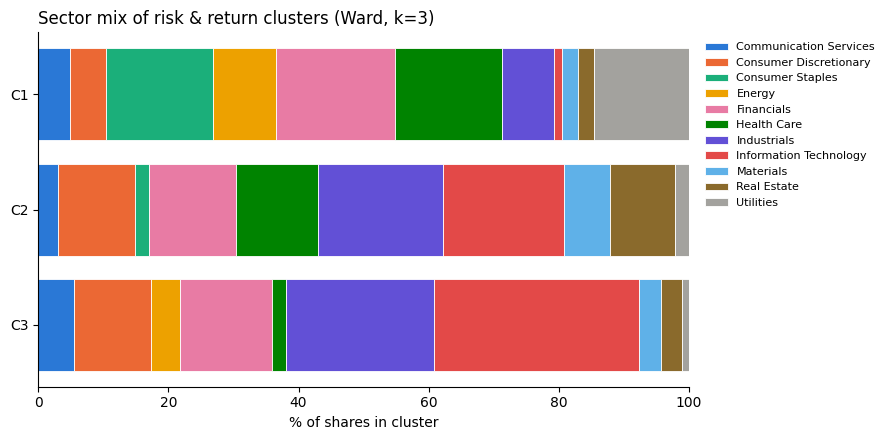

In [128]:
# One fixed colour per sector
SECTOR_COLOURS = dict(zip(sorted(data["GICS Sector"].unique()),
                          ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                           "#6250d6", "#e34948", "#5fb1e8", "#8a6a2c", "#a3a29e"]))

# Stacked bar of sector mix per cluster
def sector_bar(pct, title, path):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    left = np.zeros(pct.shape[1])
    for sector in pct.index:
        vals = pct.loc[sector].values
        ax.barh([f"C{c}" for c in pct.columns], vals, left=left, color=SECTOR_COLOURS[sector],
                edgecolor="white", linewidth=0.6, label=sector)
        left += vals
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% of shares in cluster")
    ax.set_title(title, loc="left"); ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
    ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

# Risk & return clusters
sector_bar(sec_rr_pct, f"Sector mix of risk & return clusters (Ward, k={K_WARD_RR})", "figures/3_2_sector_rr.png")

### (f) Sector mix: trading-activity clusters

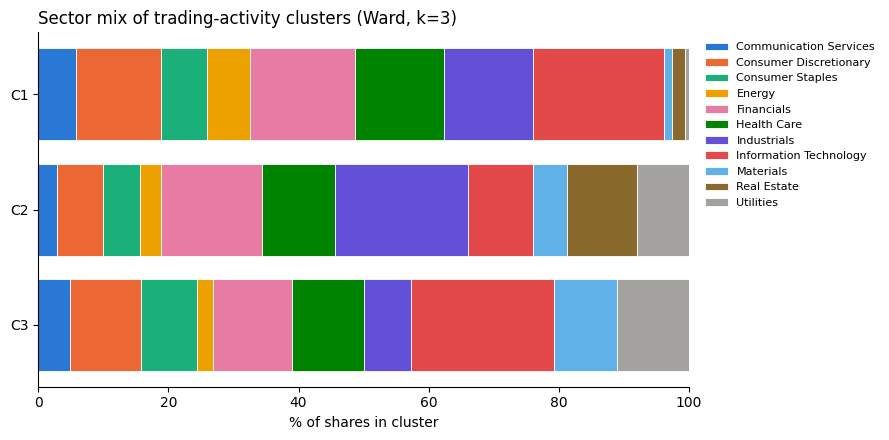

In [129]:
# Trading activity clusters
sector_bar(sec_rfm_pct, f"Sector mix of trading-activity clusters (Ward, k={K_WARD_RFM})", "figures/3_2_sector_rfm.png")

## 3.2.2 Sensitivity findings and business uses
### (a) Sensitivity summary

In [130]:
from scipy.optimize import linear_sum_assignment

# Shares that change cluster, after matching clusters one-to-one
def shares_changing(a, b):
    """Shares outside the best one-to-one matching of clusters (label numbers are arbitrary)."""
    ct = pd.crosstab(a, b).values
    rows, cols = linear_sum_assignment(-ct)
    return int(ct.sum() - ct[rows, cols].sum())

# Strongest correlation among R, F and log1p(M) (excluding the diagonal)
pearson_off = corr_pearson.where(~np.eye(3, dtype=bool)).abs().stack()
# Sensitivity results in one table
sensitivity_summary = pd.DataFrame([
    ("Strongest Pearson correlation among R, F, log1p(M)", f"{pearson_off.max():.3f}", f"{pearson_off.idxmax()[0]} vs {pearson_off.idxmax()[1]}"),
    ("Strongest Spearman correlation", f"{corr_spearman.where(~np.eye(3, dtype=bool)).abs().stack().max():.3f}", "rank-based check"),
    ("ARI full RFM vs R+F only (Ward, same k, same shares)", f"{ari_rf:.3f}", "1 = identical membership"),
    ("Shares that change cluster when M is removed", shares_changing(ward_rfm, ward_rf), f"of {len(data)}"),
    ("ARI Ward vs K-Means (trading activity)", f"{adjusted_rand_score(ward_rfm, km_rfm):.3f}", "algorithm agreement"),
], columns=["measure", "value", "note"])
sensitivity_summary.to_csv("logs/3_2_sensitivity_summary.csv", index=False)
sensitivity_summary

,measure,value,note
0,"Strongest Pearson correlation among R, F, log1...",0.346,R_days vs F_count
1,Strongest Spearman correlation,0.196,rank-based check
2,"ARI full RFM vs R+F only (Ward, same k, same s...",0.291,1 = identical membership
3,Shares that change cluster when M is removed,165,of 486
4,ARI Ward vs K-Means (trading activity),0.318,algorithm agreement


### (b) Market-wide vs share-specific busy days
Market-wide day: more than 10% of shares have an event.

In [131]:
# A day is market-wide if more than 10% of shares have an event
MARKET_WIDE_SHARE = 0.10
busy_per_day = event.loc[window].sum(axis=1)
market_wide_days = busy_per_day[busy_per_day > MARKET_WIDE_SHARE * len(retained)].index

# Split events into market-wide and share-specific
ev_window = event.loc[window]
specific = ev_window.drop(index=market_wide_days)
print("Market-wide days in the window:", [d.date() for d in market_wide_days])
print(f"Busy share-days in window: {int(ev_window.values.sum())} | on market-wide days: "
      f"{int(ev_window.loc[market_wide_days].values.sum())} | share-specific: {int(specific.values.sum())}")

# Shares with share-specific events, most recent and most frequent first
watch = pd.DataFrame({"share_specific_events": specific.sum(),
                      "latest_specific_event": specific.apply(lambda c: c[c].index.max())})
watch = watch[watch.share_specific_events > 0].join(data[["Security", "GICS Sector"]])
print("Shares with at least one share-specific busy day:", len(watch))
watch.sort_values(["share_specific_events", "latest_specific_event"], ascending=False).head(10)

Market-wide days in the window: [datetime.date(2024, 10, 31), datetime.date(2024, 11, 6), datetime.date(2024, 11, 25), datetime.date(2024, 12, 20)]
Busy share-days in window: 1453 | on market-wide days: 669 | share-specific: 784
Shares with at least one share-specific busy day: 390


,share_specific_events,latest_specific_event,Security,GICS Sector
Ticker,,,,
CI,7,2024-12-18,Cigna,Health Care
HSY,7,2024-12-11,Hershey Company (The),Consumer Staples
UNH,6,2024-12-17,UnitedHealth Group,Health Care
HON,6,2024-12-16,Honeywell Technologies,Industrials
AJG,5,2024-12-27,Arthur J. Gallagher & Co.,Financials
WDC,5,2024-12-19,Western Digital,Information Technology
FOXA,5,2024-12-18,Fox Corporation (Class A),Communication Services
XEL,5,2024-12-18,Xcel Energy,Utilities
AVGO,5,2024-12-17,Broadcom,Information Technology


### (c) Busy days per session

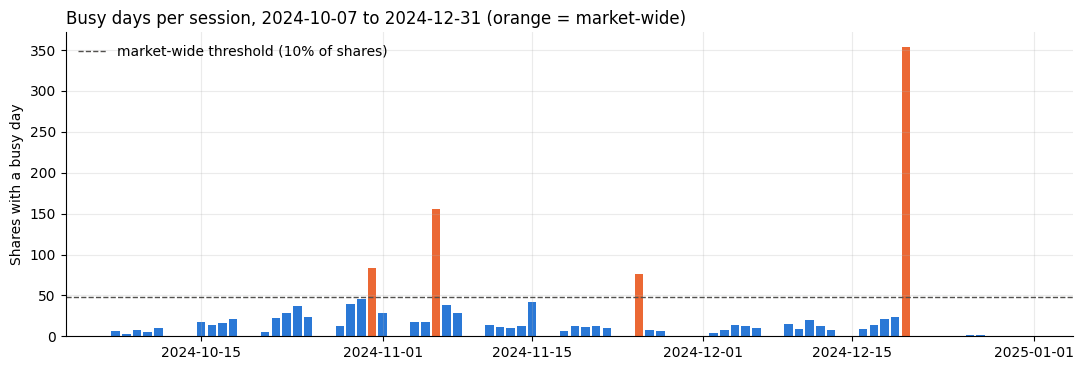

In [132]:
# Shares with an event per session; orange = market-wide day
fig, ax = plt.subplots(figsize=(11, 3.8))
colours = [PALETTE[1] if d in market_wide_days else PALETTE[0] for d in busy_per_day.index]
ax.bar(busy_per_day.index, busy_per_day.values, color=colours, width=0.8)
ax.axhline(MARKET_WIDE_SHARE * len(retained), color="#52514e", ls="--", lw=1,
           label=f"market-wide threshold ({MARKET_WIDE_SHARE:.0%} of shares)")
ax.set_ylabel("Shares with a busy day"); ax.legend(frameon=False)
ax.set_title(f"Busy days per session, {window[0].date()} to {window[-1].date()} (orange = market-wide)", loc="left")
tidy(ax); plt.tight_layout(); plt.savefig("figures/3_2_busy_days_per_session.png", dpi=150); plt.show()

### (d) Return dependencies within and between clusters

In [133]:
# Correlation of weekly returns between every pair of shares
ret_corr = weekly_ret[data.index].corr()
groups = pd.Series(ward_rr, index=data.index)

# Average correlation within a cluster (a = b) or between two clusters
def avg_corr(a, b):
    block = ret_corr.loc[groups.index[groups == a], groups.index[groups == b]].values
    if a == b:
        block = block[~np.eye(len(block), dtype=bool)]        # ignore each share's correlation with itself
    return block.mean()

clusters = sorted(groups.unique())
# Within/between-cluster correlation table
dependency = pd.DataFrame([[avg_corr(a, b) for b in clusters] for a in clusters],
                          index=[f"C{c}" for c in clusters], columns=[f"C{c}" for c in clusters])
dependency.to_csv("logs/3_2_return_dependency.csv")
# Average across all pairs of shares
all_pairs = ret_corr.values[~np.eye(len(ret_corr), dtype=bool)]
print(f"Average pairwise weekly-return correlation, all shares: {all_pairs.mean():.3f}")
print(f"Share of pairs with positive correlation: {(all_pairs > 0).mean():.1%}")
print("Average correlation within (diagonal) and between (off-diagonal) risk & return clusters:")
dependency.round(3)

Average pairwise weekly-return correlation, all shares: 0.300
Share of pairs with positive correlation: 98.6%
Average correlation within (diagonal) and between (off-diagonal) risk & return clusters:


,C1,C2,C3
C1,0.281000,0.256000,0.224000
C2,0.256000,0.363000,0.348000
C3,0.224000,0.348000,0.374000


## 3.2.3 Critical evaluation
### (a) Dividend effect (price-index benchmark)

In [134]:
# Weekly returns from Close (price only, no dividends)
close_weekly = close_w[retained].resample("W-FRI").last().loc[weekly_adj.index]
price_only_ret = close_weekly.pct_change(fill_method=None).iloc[1:]
# Extra mean return from dividends; beta recalculated on the price-only basis
dividend_effect = weekly_ret.mean() - price_only_ret.mean()
beta_price_only = price_only_ret.apply(lambda s: s.cov(gspc_ret)) / gspc_ret.var()

print(f"Median extra weekly return from dividends: {dividend_effect.median():.4%} "
      f"(about {dividend_effect.median() * 52:.2%} a year); largest: {dividend_effect.max():.4%}")
print(f"Shares with no dividend effect: {int((dividend_effect.abs() < 1e-6).sum())}")
print(f"Median |beta(Adj Close) - beta(Close)|: {(beta - beta_price_only).abs().median():.4f}")

Median extra weekly return from dividends: 0.0293% (about 1.53% a year); largest: 0.1516%
Shares with no dividend effect: 94
Median |beta(Adj Close) - beta(Close)|: 0.0013


### (b) Stability across the two halves of the period

In [135]:
# Split the weekly returns into two halves
half = N_WEEKS // 2
h1, h2 = weekly_ret.iloc[:half], weekly_ret.iloc[half:]
g1, g2 = gspc_ret.iloc[:half], gspc_ret.iloc[half:]
# Mean return and beta in each half
halves = pd.DataFrame({
    "return_1st_half": h1.mean(), "return_2nd_half": h2.mean(),
    "beta_1st_half": h1.apply(lambda s: s.cov(g1)) / g1.var(),
    "beta_2nd_half": h2.apply(lambda s: s.cov(g2)) / g2.var(),
})
print(f"Halves: {h1.index[0].date()}-{h1.index[-1].date()} ({len(h1)} weeks) | {h2.index[0].date()}-{h2.index[-1].date()} ({len(h2)} weeks)")
# Rank correlation between halves (stability over time)
print(f"Rank correlation of mean return, 1st vs 2nd half: {halves.return_1st_half.corr(halves.return_2nd_half, method='spearman'):.3f}")
print(f"Rank correlation of beta, 1st vs 2nd half:        {halves.beta_1st_half.corr(halves.beta_2nd_half, method='spearman'):.3f}")

# Medians by full-period risk & return cluster
halves["cluster"] = pd.Series(ward_rr, index=data.index)
print("\nMedian by risk & return cluster (full-period clusters):")
print(halves.groupby("cluster").median().round(4).to_string())

Halves: 2021-01-15-2022-12-30 (103 weeks) | 2023-01-06-2024-12-27 (104 weeks)
Rank correlation of mean return, 1st vs 2nd half: -0.144
Rank correlation of beta, 1st vs 2nd half:        0.796

Median by risk & return cluster (full-period clusters):
         return_1st_half  return_2nd_half  beta_1st_half  beta_2nd_half
cluster                                                                
1               0.003000         0.002500       0.630200       0.443500
2               0.000700         0.002500       1.029800       1.055200
3               0.002800         0.008300       1.189600       1.285100


### (c) Limitations evidence

In [136]:
# Limitations with evidence from this run
limitations = pd.DataFrame([
    ("Survivorship bias", f"current list of {len(sp500)} constituents applied to 2021-2024; firms removed before retrieval are absent", "1.2.6"),
    ("Exclusions", f"{len(sp500) - len(retained)} constituents excluded (5 failed, 10 late listings, 2 zero-volume)", "1.2.5, 1.5.5"),
    ("Price basis", f"dividends add a median {dividend_effect.median():.4%} per week to share returns but not to ^GSPC", "3.2.3 (a)"),
    ("Return dependencies", f"average pairwise weekly-return correlation {all_pairs.mean():.2f}", "3.2.2 (d)"),
    ("Feature overlap", f"strongest |Pearson r| among R, F, log1p(M) = {pearson_off.max():.2f}", "2.5.1"),
    ("Market-wide events", f"{int(rfm['last_event_date'].value_counts().iloc[0])} of {len(rfm)} shares share the latest event date "
                           f"{rfm['last_event_date'].value_counts().index[0].date()}", "1.5.2"),
    ("Liquidity proxy", "M = Close x Volume; no bid-ask spread or price impact measured", "1.4.3"),
    ("Stability over time", f"Spearman rho of beta between halves = {halves.beta_1st_half.corr(halves.beta_2nd_half, method='spearman'):.2f}", "3.2.3 (b)"),
    ("Cluster strength", f"overall silhouettes in the weak band; per-cluster means {min(per_cluster_sil.mean_silhouette):.2f} to {max(per_cluster_sil.mean_silhouette):.2f}", "2.2-2.3"),
], columns=["limitation", "evidence from this run", "section"])
limitations.to_csv("logs/3_2_limitations_evidence.csv", index=False)
pd.set_option("display.max_colwidth", None)
limitations

,limitation,evidence from this run,section
0,Survivorship bias,current list of 503 constituents applied to 2021-2024; firms removed before retrieval are absent,1.2.6
1,Exclusions,"17 constituents excluded (5 failed, 10 late listings, 2 zero-volume)","1.2.5, 1.5.5"
2,Price basis,dividends add a median 0.0293% per week to share returns but not to ^GSPC,3.2.3 (a)
3,Return dependencies,average pairwise weekly-return correlation 0.30,3.2.2 (d)
4,Feature overlap,"strongest |Pearson r| among R, F, log1p(M) = 0.35",2.5.1
5,Market-wide events,353 of 486 shares share the latest event date 2024-12-20,1.5.2
6,Liquidity proxy,M = Close x Volume; no bid-ask spread or price impact measured,1.4.3
7,Stability over time,Spearman rho of beta between halves = 0.80,3.2.3 (b)
8,Cluster strength,overall silhouettes in the weak band; per-cluster means 0.18 to 0.38,2.2-2.3


# 3.3 Export

In [137]:
# Add Task 3 details to the metadata file
metadata.update({
    "run_id": RUN_ID,
    "data_mart": mart_path,
    "data_mart_tables": counts,
    "market_wide_day_threshold": MARKET_WIDE_SHARE,
    "ari_rr_vs_rfm_ward": round(adjusted_rand_score(ward_rr, ward_rfm), 4),
})
with open("logs/acquisition_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=str)
print("Metadata saved with", len(metadata), "fields")

Metadata saved with 41 fields


In [138]:
# Zip all outputs and download them
!zip -qr cwk1_all_outputs.zip data logs figures requirements.txt

from google.colab import files
files.download("cwk1_all_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>